# Taller Práctico: Detección y Análisis de Olas de Calor Marinas (OCM)

**Caso de Estudio: Costa Peruana durante 1991–2025**

---

### Contenido

1. Configuración del entorno y dependencias
2. Marco metodológico: algoritmo de detección de OCM
3. Datos: NOAA OISST v2.1
4. Detección de OCM con el paquete `xhw`
5. Análisis espacial y temporal de las OCM en la costa peruana
6. Comparación con la librería de Eric Oliver (`marineHeatWaves`)
7. Resumen y perspectivas

## 1. Configuración del Entorno y Dependencias

En este taller trabajamos con el stack científico estándar de Python para geociencias (`xarray`, `numpy`, `pandas`, `matplotlib`, `h5netcdf`), la librería de alto rendimiento `xhw` y el paquete de referencia `marineHeatWaves` (Eric Oliver).

**Entorno de referencia.** Las versiones están fijadas en `requirements.txt` y coinciden con las de Google Colab (Python 3.13, numpy 2.4.6, pandas 2.2.3, xarray 2025.12.0, matplotlib 3.10.0, scipy 1.16.3). Para crear el entorno local:

```bash
python -m venv remohes-env          # o: conda create -p ./remohes-env python=3.13
remohes-env/Scripts/activate        # Linux/macOS: source remohes-env/bin/activate
pip install -r requirements.txt
```

> `marineHeatWaves` no se instala con `pip`: la versión publicada falla con numpy ≥ 2, por lo que usamos la copia parcheada en `vendor/marineHeatWaves.py` (GPL-3.0, el parche está documentado en su encabezado).

La celda siguiente imprime las versiones activas para que puedas compararlas con las de referencia.

In [1]:
# Entorno de referencia: pip install -r requirements.txt
from pathlib import Path
import platform
import sys
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import xarray as xr
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap

import xhw

# Módulos del taller: copia parcheada de marineHeatWaves (vendor/) y utilidades (scripts/)
sys.path[:0] = [str(Path("vendor").resolve()), str(Path("scripts").resolve())]
import marineHeatWaves as mhw_oliver
from especificaciones_ocm import especificaciones_ocm
from descargar_oisst import descargar

# Paleta común con los esquemas: T_m azul, T_90 amarillo, OCM rojo, categorías I-IV
C_CLIM, C_UMBRAL, C_OCM = "#1f77b4", "#e3b100", "#d62728"
C_CAT = ["#ffe08a", "#f7a541", "#e0512c", "#8c1c13"]
NOMBRES_CAT = ["I Moderada", "II Fuerte", "III Severa", "IV Extrema"]


def trazar_sst(ax, tiempo, sst, en_ocm, lw=1.3, etiqueta="SST observada"):
    """SST en negro y en rojo durante la OCM (misma convención que los esquemas)."""
    sst, en_ocm = np.asarray(sst), np.asarray(en_ocm, dtype=bool)
    roja = np.where(en_ocm | np.r_[en_ocm[1:], False] | np.r_[False, en_ocm[:-1]], sst, np.nan)
    ax.plot(tiempo, sst, color="black", lw=lw, label=etiqueta, zorder=4)
    ax.plot(tiempo, roja, color=C_OCM, lw=lw + 0.9, label="SST durante la OCM", zorder=5)

referencia = {"numpy": "2.4.6", "pandas": "2.2.3", "xarray": "2025.12.0",
              "matplotlib": "3.10.0", "scipy": "1.16.3"}
activas = {"numpy": np.__version__, "pandas": pd.__version__, "xarray": xr.__version__,
           "matplotlib": matplotlib.__version__, "scipy": scipy.__version__}

print(f"Python {platform.python_version()} ({sys.platform})")
for nombre, version in activas.items():
    marca = "" if version == referencia[nombre] else f"   <- referencia: {referencia[nombre]}"
    print(f"• {nombre:<11} {version}{marca}")
print(f"• {'xhw':<11} {xhw.__version__}")
print(f"• marineHeatWaves (vendor): {Path(mhw_oliver.__file__).name}")

Python 3.13.18 (win32)
• numpy       2.4.6
• pandas      2.2.3
• xarray      2025.12.0
• matplotlib  3.10.0
• scipy       1.16.3
• xhw         0.0.1
• marineHeatWaves (vendor): marineHeatWaves.py


## 2. Marco Metodológico: Algoritmo de Detección de OCM

Una **Ola de Calor Marina (OCM)** es un período prolongado y anómalamente cálido en el océano. Siguiendo a **Hobday et al. (2016)**, un evento queda determinado por tres componentes:

1. **Línea base climatológica media** ($T_m$): media estacional calculada para cada día del año (de 1 a 366) sobre un período de referencia de 30 años (1991–2020).
2. **Umbral percentil 90** ($T_{90}$): percentil 90 móvil diario calculado dentro de una ventana de 11 días centrada en cada día del año.
3. **Criterio de duración y continuidad:** excedencia continua, SST $> T_{90}$, durante al menos **5 días consecutivos**.

---

### 2.1 Definición Canónica de un Evento de OCM
A continuación se ilustra la anatomía de un evento de OCM (la serie se dibuja en rojo mientras dura la OCM):

![Esquema 1A: Definición de una OCM](assets/esquema_1a_definicion.png)

- **Inicio, fin y duración** ($t_s$, $t_e$, $D$): primer y último día sobre $T_{90}$; la OCM exige $D \geq 5$ días. Un pico más corto, aunque supere el umbral, **no es OCM**.
- **Intensidad:** anomalía $T - T_m$ respecto de la climatología (no del umbral).
- **Intensidad máxima** ($i_{max}$): mayor anomalía durante el evento (°C).
- **Intensidad acumulada** ($i_{cum}$): suma de las anomalías diarias del evento (°C·días), el área sombreada.
- **Diferencia umbral–climatología**, $\Delta T = T_{90} - T_m$: distancia entre umbral y climatología; varía a lo largo del año y es la base de las categorías (2.3).

---

### 2.2 Reglas de Continuidad y Manejo de Brechas
Para modelar adecuadamente la persistencia térmica oceánica, se aplican reglas de unión y separación:

![Esquema 1B: Reglas de duración y brecha](assets/esquema_1b_reglas_brecha.png)

Primero se identifican las rachas de al menos 5 días sobre $T_{90}$; después se unen las que están separadas por **2 días o menos**. Son los tres ejemplos de Hobday et al. (2016):

- **5 días cálidos, 2 frescos, 6 cálidos:** brecha de 2 días → **una** OCM de 13 días (los días de la brecha cuentan).
- **5 cálidos, 1 fresco, 2 cálidos:** la racha final de 2 días no califica por sí sola, así que no se une → una OCM de 5 días.
- **5 cálidos, 4 frescos, 6 cálidos:** brecha de 4 días → **dos** OCM (5 y 6 días).

### 2.3 Categorías de Olas de Calor Marinas (Hobday et al., 2018)
Para comunicar la severidad ecológica, Hobday et al. (2018) definieron cuatro categorías basadas en múltiplos de la diferencia entre umbral y climatología, $\Delta T = T_{90} - T_m$:

![Esquema 2: Categorías de OCM](assets/esquema_2_categorias.png)

- **Categoría I (Moderada):** de 1 a 2 veces $\Delta T$
- **Categoría II (Fuerte):** de 2 a 3 veces $\Delta T$
- **Categoría III (Severa):** de 3 a 4 veces $\Delta T$
- **Categoría IV (Extrema):** más de 4 veces $\Delta T$

Las categorías miden el **pico** de un evento. La otra medida habitual de severidad es la **intensidad acumulada** ($i_{cum}$) (2.1), que combina intensidad y duración: un evento moderado pero largo puede acumular más calor que uno severo y breve. Por eso en la sección 4 analizamos ambas.

---

### 2.4 Cálculo de la climatología y el umbral
`xhw` calcula $T_m$ y $T_{90}$ para cada día del año en tres pasos:

![Esquema: Cálculo de Climatología y Umbrales](assets/esquema_climatologia_umbral.png)

1. **Ventana de 11 días** (día $d \pm 5$): para cada día del año se juntan los valores de esa ventana en los 30 años de referencia (≈ 330 muestras).
2. **Media y percentil 90:** $T_m$ es la media de esas muestras y $T_{90}$ su percentil 90, con la definición tipo 7 de Hyndman y Fan (1996), la que usa `numpy` por defecto ([artículo](https://doi.org/10.1080/00031305.1996.10473566)).
3. **Suavizado circular de 31 días:** una media móvil de 31 días sobre los 366 días del año. Es circular: el 31 de diciembre empalma con el 1 de enero sin saltos.

**De la climatología mensual a la diaria.** Las climatologías habituales son mensuales: un valor de la media (y, si se quiere, del P90) para cada mes. Pero la detección de OCM compara la SST de **cada día** con su umbral, así que necesita una climatología diaria. Partiendo de una mensual, lo usual es ubicar cada valor a mitad de mes e interpolar linealmente entre meses vecinos (de diciembre a enero, de forma circular).

La figura muestra esos dos pasos con los datos de Ilo y compara el resultado con la climatología diaria de Hobday et al. (2016). Se parecen, pero la mensual interpolada se aparta hasta 0,1 °C en $T_m$ y 0,2 °C en $T_{90}$, sobre todo en los cambios de estación. Como $\Delta T$ es del orden de 1 °C, esa diferencia puede adelantar o retrasar uno o dos días el inicio o el fin de un evento; por eso Hobday et al. (2016) calculan la climatología directamente para cada día del año.

![De la climatología mensual a la diaria](assets/esquema_climatologia_mensual.png)

## 3. Datos: NOAA OISST v2.1

### 3.1 Producto y dominio de estudio

Trabajamos con el producto **NOAA 1/4° Daily Optimum Interpolation Sea Surface Temperature (OISST v2.1)**, documentado por **[Huang et al. (2021, *J. Climate*)](https://doi.org/10.1175/JCLI-D-20-0166.1)**.

![Datos satelitales NOAA OISST v2.1](assets/esquema_oisst.png)

**Dominio de estudio: todo el litoral peruano**

El litoral peruano se extiende desde los 3.4°S (Boca de Capones, Tumbes) hasta los 18.35°S (Pascana del Hueso, Tacna). Al sur del Callao la costa gira hacia el sureste (Pisco 76.2°W, Ilo 71.3°W), por eso el dominio debe llegar hasta 70°W:

| | Bordes del dominio | Centros de píxel |
| :--- | :--- | :--- |
| Latitud | 18°S – 3°S | −17.875, −17.625, …, −3.125 (60 valores) |
| Longitud | 85°W – 70°W | −84.875, −84.625, …, −70.125 (60 valores) |
| Tiempo | 1991-01-01 – 2025-12-31 | diario (12 784 días) |

- **Costa Norte (3°S–7°S):** Tumbes, Piura, Lambayeque (ej. Paita: 5.08°S).
- **Costa Centro (7°S–12°S):** La Libertad, Áncash, Lima (ej. Chimbote: 9.07°S, Callao: 12.05°S).
- **Costa Sur (12°S–18°S):** Ica, Arequipa, Moquegua, Tacna (ej. Pisco: 13.71°S, San Juan de Marcona: 15.36°S, Ilo: 17.64°S).

**¿Qué representan `lat` y `lon`? Centros de píxel**

En OISST v2.1 las coordenadas son los **centros** de celdas de 0,25° × 0,25°: el valor en (−9.125, −78.625) representa el promedio sobre la celda [−9.25, −9.00] × [−78.75, −78.50]. Consecuencias prácticas:
- OISST trae la **máscara de tierra ya aplicada**: las celdas de tierra no tienen dato en ninguna fecha. Por eso la máscara de océano (`domain_mask`) sale de los propios datos.
- Un puerto casi nunca coincide con un centro: usamos el **píxel oceánico más cercano**, es decir, la celda con dato más próxima.
- Al recortar con `slice(-18, -3)` sobre los centros se obtienen exactamente las celdas cuyo borde cae dentro del dominio.
- `imshow` de xarray dibuja cada píxel centrado en su coordenada, así que los mapas quedan bien georreferenciados.

> El archivo `data/oisst_peru_1991_2025.nc` (≈40 MB) viene con el repositorio. Si no está, la celda siguiente lo regenera con `scripts/descargar_oisst.py` desde el repositorio público Icechunk de source.coop (≈30–40 min).

In [2]:
ARCHIVO_DATOS = Path("data/oisst_peru_1991_2025.nc")

if not ARCHIVO_DATOS.is_file():
    import subprocess
    print(f"No se encontró {ARCHIVO_DATOS}. Descargando NOAA OISST v2.1 (puede tardar ~30-40 min)...")
    subprocess.run([sys.executable, "scripts/descargar_oisst.py", "--salida", str(ARCHIVO_DATOS)], check=True)

# Cargamos todo en memoria (≈180 MB) para que los tiempos de cómputo no incluyan lectura de disco
ds = xr.open_dataset(ARCHIVO_DATOS).load()
ds["domain_mask"] = ds["sst"].notnull().any("time")   # True = océano: OISST trae la tierra como NaN en todas las fechas

dlat = float(ds.lat.diff("lat").mean()); dlon = float(ds.lon.diff("lon").mean())
print(f"Dimensiones: {dict(ds.sizes)}  |  celdas oceánicas: {int(ds.domain_mask.sum())} de {ds.lat.size * ds.lon.size}")
print(f"Periodo: {str(ds.time.values[0])[:10]} a {str(ds.time.values[-1])[:10]}")
print(f"Centros de píxel  -> lat [{float(ds.lat.min()):.3f}, {float(ds.lat.max()):.3f}], lon [{float(ds.lon.min()):.3f}, {float(ds.lon.max()):.3f}]")
print(f"Bordes del dominio -> lat [{float(ds.lat.min()) - dlat/2:.2f}, {float(ds.lat.max()) + dlat/2:.2f}], "
      f"lon [{float(ds.lon.min()) - dlon/2:.2f}, {float(ds.lon.max()) + dlon/2:.2f}]  (resolución {dlat}° x {dlon}°)")

Dimensiones: {'time': 12784, 'lat': 60, 'lon': 60}  |  celdas oceánicas: 1805 de 3600
Periodo: 1991-01-01 a 2025-12-31
Centros de píxel  -> lat [-17.875, -3.125], lon [-84.875, -70.125]
Bordes del dominio -> lat [-18.00, -3.00], lon [-85.00, -70.00]  (resolución 0.25° x 0.25°)


**Descarga en tiempo real.** El script de descarga también se usa desde Python: `descargar(inicio, fin, lat, lon)` recibe las fechas y los **bordes** del dominio en grados (oeste y sur negativos) y devuelve un `xarray.Dataset` con el mismo formato que el archivo del taller. Lo usamos para bajar el **año en curso hasta hoy**, en el mismo dominio, directamente del servidor: estos datos no vienen con el repositorio, así que la celda comprueba que el flujo funciona con datos al día (≈ 2 min). Con ellos, la sección 3.2 dibuja el mapa del último mes junto al promedio histórico.

> Los días más recientes de OISST son **preliminares**: NOAA los reemplaza por la versión final unas dos semanas después.


In [3]:
# Año en curso, del 1 de enero a hoy, en el mismo dominio (no se guarda en disco)
hoy = pd.Timestamp.now().normalize()
print(f"Descargando NOAA OISST v2.1 del {hoy.year}-01-01 al {hoy:%Y-%m-%d}...")
t0 = time.perf_counter()
try:
    ds_2026 = descargar(f"{hoy.year}-01-01", f"{hoy:%Y-%m-%d}", lat=(-18, -3), lon=(-85, -70))
    print(f"Listo en {time.perf_counter() - t0:.0f} s  |  dimensiones: {dict(ds_2026.sizes)}  |  "
          f"{str(ds_2026.time.values[0])[:10]} a {str(ds_2026.time.values[-1])[:10]}")
except Exception as error:   # sin conexión: el resto del cuaderno no depende de esta descarga
    ds_2026 = None
    print(f"No se pudo descargar: {error}")


Descargando NOAA OISST v2.1 del 2026-01-01 al 2026-11-20...


Listo en 61 s  |  dimensiones: {'time': 320, 'lat': 60, 'lon': 60}  |  2026-01-01 a 2026-11-16


### 3.2 Visualización del dominio y selección de puertos

Antes de calcular anomalías, exploramos el campo térmico medio de la Corriente de Humboldt frente a la costa de Perú:
- Visualizamos la temperatura promedio multianual (1991–2025) y, a su derecha, la de los últimos 30 días descargados de 2026, con la misma escala de color.
- Ubicamos puertos de norte a sur: **Paita, Chicama, Salaverry, Chimbote, Callao, Pisco, San Juan de Marcona e Ilo**, y para cada uno buscamos el **píxel oceánico más cercano** (el centro de celda que usaremos en el análisis).
- Usamos un aspecto 1:1 (`ax.set_aspect('equal')`) para que los píxeles no se deformen.

Las figuras del cuaderno son imágenes estáticas. Para analizar otro punto basta con llamar a `pixel_oceanico(lat, lon)` con sus coordenadas: devuelve la celda oceánica más cercana.

Puerto                Puerto (lat, lon)   Centro del píxel usado   Distancia
Paita                (  -5.08,  -81.11)   (  -4.875,  -81.125)      22.9 km
Chicama              (  -7.70,  -79.44)   (  -7.875,  -79.375)      20.7 km
Salaverry            (  -8.22,  -78.98)   (  -8.125,  -79.125)      19.1 km
Chimbote             (  -9.07,  -78.59)   (  -9.125,  -78.625)       7.2 km
Callao               ( -12.05,  -77.15)   ( -12.125,  -77.125)       8.8 km
Pisco                ( -13.71,  -76.22)   ( -13.625,  -76.375)      19.2 km
San Juan de Marcona  ( -15.36,  -75.17)   ( -15.375,  -75.125)       5.1 km
Ilo                  ( -17.64,  -71.34)   ( -17.625,  -71.375)       4.1 km


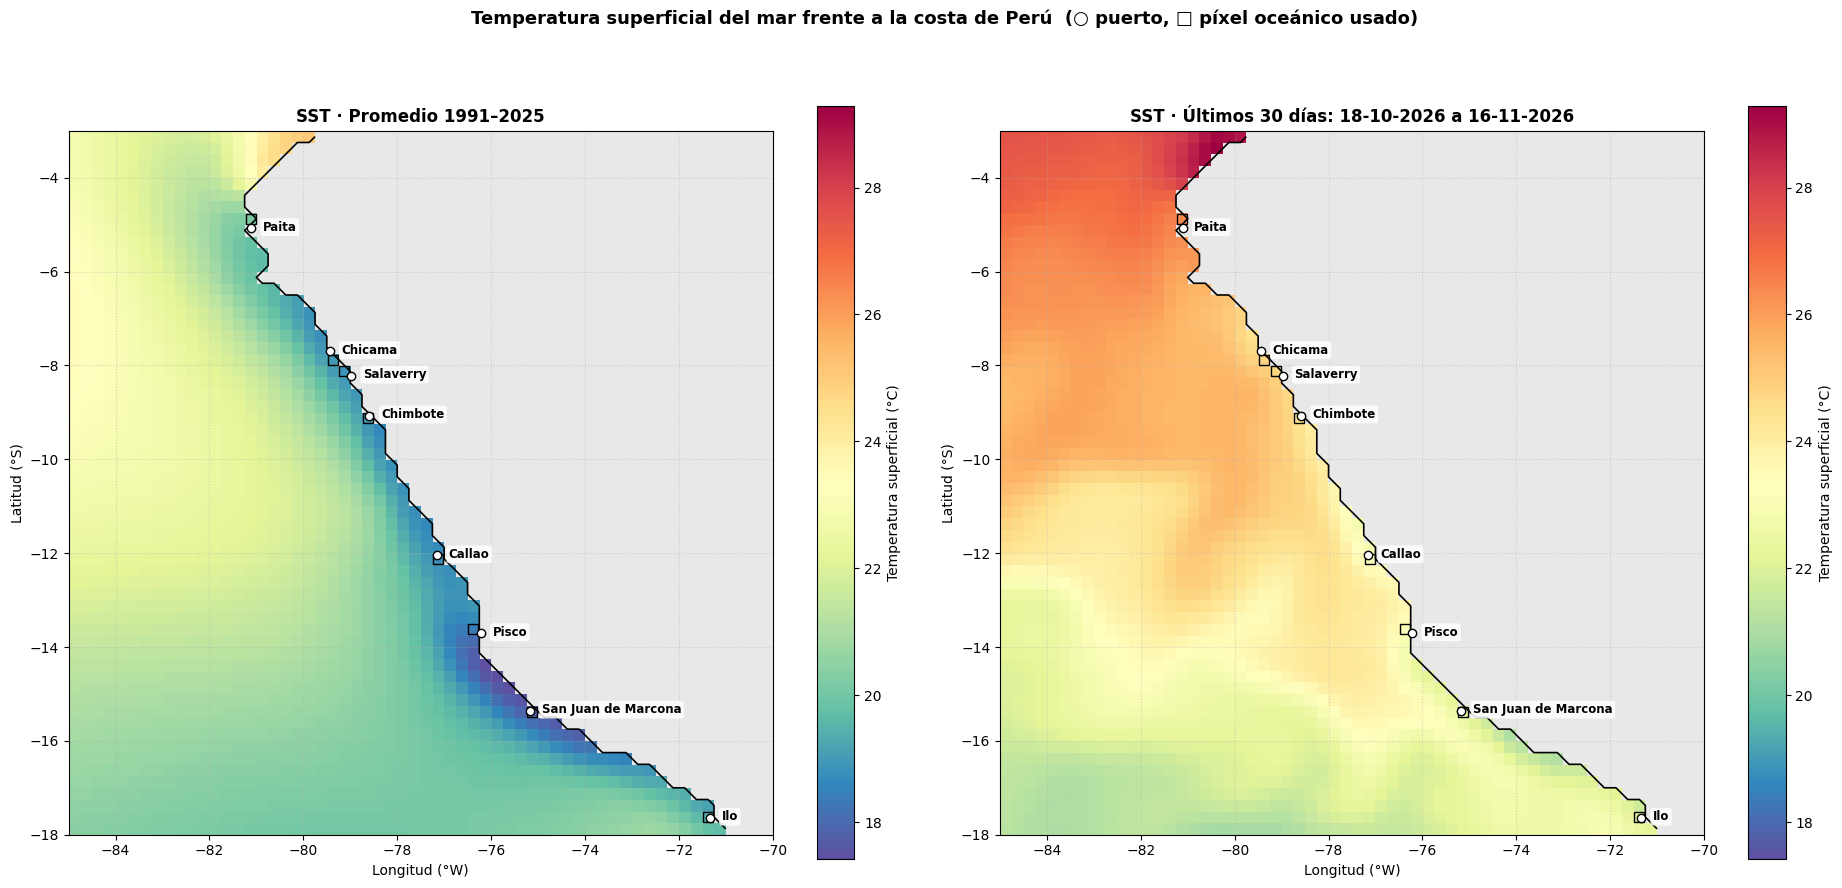

In [4]:
# 1. Calcular el campo promedio histórico de temperatura (1991-2025)
sst_mean_map = ds["sst"].mean(dim="time")

# 2. Puertos peruanos de referencia (coordenadas aproximadas del puerto)
puertos_peru = {
    "Paita": (-5.08, -81.11),
    "Chicama": (-7.70, -79.44),
    "Salaverry": (-8.22, -78.98),
    "Chimbote": (-9.07, -78.59),
    "Callao": (-12.05, -77.15),
    "Pisco": (-13.71, -76.22),
    "San Juan de Marcona": (-15.36, -75.17),
    "Ilo": (-17.64, -71.34),
}


def pixel_oceanico(lat, lon):
    """Devuelve (ilat, ilon, lat_c, lon_c, dist_km) del centro de celda oceánica más cercano."""
    LAT, LON = np.meshgrid(ds["lat"].values, ds["lon"].values, indexing="ij")
    dy = (LAT - lat) * 111.2
    dx = (LON - lon) * 111.2 * np.cos(np.deg2rad(lat))
    dist = np.where(ds["domain_mask"].values, np.hypot(dx, dy), np.inf)
    ilat, ilon = np.unravel_index(np.argmin(dist), dist.shape)
    return int(ilat), int(ilon), float(LAT[ilat, ilon]), float(LON[ilat, ilon]), float(dist[ilat, ilon])


pixeles = {nombre: pixel_oceanico(*coord) for nombre, coord in puertos_peru.items()}
print(f"{'Puerto':<20} {'Puerto (lat, lon)':>18}   {'Centro del píxel usado':>22}   Distancia")
for nombre, (p_lat, p_lon) in puertos_peru.items():
    _, _, c_lat, c_lon, d = pixeles[nombre]
    print(f"{nombre:<20} ({p_lat:7.2f}, {p_lon:7.2f})   ({c_lat:8.3f}, {c_lon:8.3f})     {d:5.1f} km")

# 3. Mapas: promedio 1991-2025 (izquierda) y último mes descargado de 2026 (derecha)
mapas = [(sst_mean_map, "Promedio 1991–2025")]
if ds_2026 is not None:
    fin = pd.Timestamp(ds_2026.time.values[-1])
    ultimo_mes = ds_2026["sst"].sel(time=slice(fin - pd.Timedelta(days=29), fin))
    mapas.append((ultimo_mes.mean("time"),
                  f"Últimos 30 días: {pd.Timestamp(ultimo_mes.time.values[0]):%d-%m-%Y} a {fin:%d-%m-%Y}"))
vmin = min(float(m.min()) for m, _ in mapas)
vmax = max(float(m.max()) for m, _ in mapas)

fig, axes = plt.subplots(1, len(mapas), figsize=(9.5 * len(mapas), 9.5), squeeze=False)
for ax, (campo, titulo) in zip(axes[0], mapas):
    ax.set_facecolor("#e8e8e8")
    campo.plot.imshow(ax=ax, cmap="Spectral_r", vmin=vmin, vmax=vmax,
                      cbar_kwargs={"label": "Temperatura superficial (°C)", "shrink": 0.85})
    ax.set_aspect("equal")
    ax.contour(ds["lon"], ds["lat"], ds["domain_mask"], levels=[0.5], colors="black", linewidths=1.2)
    # Marcadores de puertos (círculo) y del píxel oceánico usado (cuadrado)
    for nombre, (p_lat, p_lon) in puertos_peru.items():
        _, _, c_lat, c_lon, _ = pixeles[nombre]
        ax.plot(c_lon, c_lat, marker="s", color="none", markeredgecolor="black", markersize=7, zorder=5)
        ax.plot(p_lon, p_lat, marker="o", color="white", markeredgecolor="black", markersize=6, zorder=6)
        ax.text(p_lon + 0.25, p_lat - 0.05, nombre, color="black", fontsize=8.5, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.85, edgecolor="none"), zorder=7)
    ax.set_title(f"SST · {titulo}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Longitud (°W)")
    ax.set_ylabel("Latitud (°S)")
    ax.grid(True, linestyle=":", alpha=0.5)

plt.suptitle("Temperatura superficial del mar frente a la costa de Perú  (○ puerto, □ píxel oceánico usado)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 4. Detección de OCM con el paquete `xhw`

### 4.1 Especificaciones y ejecución

`xhw` describe un análisis con cuatro **contratos**:

| Contrato | Qué declara | En este taller |
| :--- | :--- | :--- |
| `SourceRef` | de dónde vienen los datos | OISST v2.1, recorte de la costa peruana |
| `GridSpec` | la malla | superficie regular lat × lon a 0,25°, solo celdas oceánicas |
| `DefinitionSpec` | qué es una OCM | SST > P90 durante ≥ 5 días, brechas ≤ 2 días, categorías de Hobday et al. (2018) |
| `BaselineSpec` | cómo se calcula la climatología | fija 1991–2020, ventana de 11 días, suavizado de 31 días, P90 tipo 7 |

`xhw` no trae perfiles predefinidos: pide declarar los cuatro contratos completos para que cada decisión quede registrada. Para no repetir unas 50 líneas, los agrupamos en `scripts/especificaciones_ocm.py`, como hacen los ejemplos de `xhw` y de `xhw-benchmark`. Sus argumentos son solo lo que cambiaría un usuario: periodo de referencia, percentil, duración mínima, brecha máxima y ventanas.

Con esos contratos, tres funciones hacen todo el trabajo sobre las 1805 celdas oceánicas: `fit_baseline` (climatología y umbral), `detect` (días de OCM) y `build_catalog` (tabla de eventos con sus métricas).

> **El día del año.** La climatología se guarda en un eje de 366 días con el 29 de febrero en la posición 60. No hace falta convertir fechas a ese eje: `detect` devuelve la SST, $T_m$ (`reference`) y $T_{90}$ (`threshold`) ya alineados con cada fecha, y `result_baseline.expand(fechas)` hace lo mismo para cualquier eje de tiempo.

Luego seleccionamos un píxel costero representativo (**Chimbote**, uno de los principales puertos pesqueros del Perú) para un análisis detallado.

In [5]:
# 1. Contratos de xhw para OCM (Hobday et al. 2016, 2018); detalle en scripts/especificaciones_ocm.py
source, grid, definition, baseline = especificaciones_ocm(periodo_referencia=("1991-01-01", "2020-12-31"))
print(f"Definición: SST {definition.comparator} P{definition.percentile:g} durante ≥ {definition.min_duration_days} días, "
      f"brechas ≤ {definition.max_gap_days} días, categorías {definition.category_scheme}")
print(f"Línea base: {baseline.method} {baseline.reference_period[0][:4]}–{baseline.reference_period[1][:4]}, "
      f"ventana {baseline.doy_window_days} d, suavizado {baseline.smoothing_window_days} d, {baseline.percentile_estimator}")
print()

# 2. Pipeline completo de xhw (climatología, detección y catálogo), midiendo su tiempo
t0_xhw = time.perf_counter()
print("1/3 Calculando climatología de base y umbrales...")
result_baseline = xhw.fit_baseline(ds=ds, variable="sst", grid=grid, baseline=baseline, definition=definition)
print("2/3 Detectando días de OCM...")
mask = xhw.detect(ds=ds, variable="sst", grid=grid, definition=definition, baseline_result=result_baseline)
print("3/3 Construyendo el catálogo de eventos...")
catalog = xhw.build_catalog(mask, analysis_mode="retrospective")
tiempo_xhw_total = time.perf_counter() - t0_xhw
print(f"Pipeline de xhw completado en {tiempo_xhw_total:.2f} s para {int(ds.domain_mask.sum())} celdas oceánicas.")

# 3. Píxel oceánico de Chimbote y sus eventos
ilat, ilon, lat_sel, lon_sel, _ = pixeles["Chimbote"]
nombre_pto_sel = "Chimbote (Áncash)"
sst_pixel = ds["sst"].isel(lat=ilat, lon=ilon)

df_all = catalog.dataset.to_dataframe()
df_eventos = df_all[(df_all["index_lat"] == ilat) & (df_all["index_lon"] == ilon)].copy()
df_eventos["start"] = pd.to_datetime(df_eventos["start"])
df_eventos["end"] = pd.to_datetime(df_eventos["end"])
df_eventos["year"] = df_eventos["start"].dt.year

print()
print(f"{nombre_pto_sel}: centro del píxel Lat {lat_sel:.3f}°, Lon {lon_sel:.3f}°")
print(f"Eventos identificados en el píxel: {len(df_eventos)}")

Definición: SST > P90 durante ≥ 5 días, brechas ≤ 2 días, categorías hobday2018
Línea base: fixed_climatology 1991–2020, ventana 11 d, suavizado 31 d, hyndman_fan_7

1/3 Calculando climatología de base y umbrales...


2/3 Detectando días de OCM...


3/3 Construyendo el catálogo de eventos...


Pipeline de xhw completado en 28.38 s para 1805 celdas oceánicas.

Chimbote (Áncash): centro del píxel Lat -9.125°, Lon -78.625°
Eventos identificados en el píxel: 51


### 4.2 Análisis Exploratorio de las Olas de Calor Marinas en Chimbote

Realizamos una exploración visual y cuantitativa integral del régimen de OCM en el puerto de Chimbote (1991–2025):
1. **Serie temporal 2023–2024:** la SST frente a $T_m$, $T_{90}$ y las bandas de categoría I–IV; la serie se dibuja en rojo mientras dura la OCM.
2. **Panel exploratorio de 4 gráficos:**
   - **A. Días con OCM por año** (1991–2025), frente a la media de 1991–2020.
   - **B. Duración de los eventos:** muchos eventos cortos y pocos muy largos (eje logarítmico).
   - **C. Duración frente a intensidad máxima** ($i_{max}$): color según la categoría y tamaño según la intensidad acumulada ($i_{cum}$).
   - **D. Intensidad máxima frente a acumulada:** la acumulada abarca tres órdenes de magnitud (eje logarítmico).
3. **Tablas:**
   - Métricas por categoría de Hobday et al. (2018).
   - Los 10 eventos más intensos registrados frente a Chimbote.


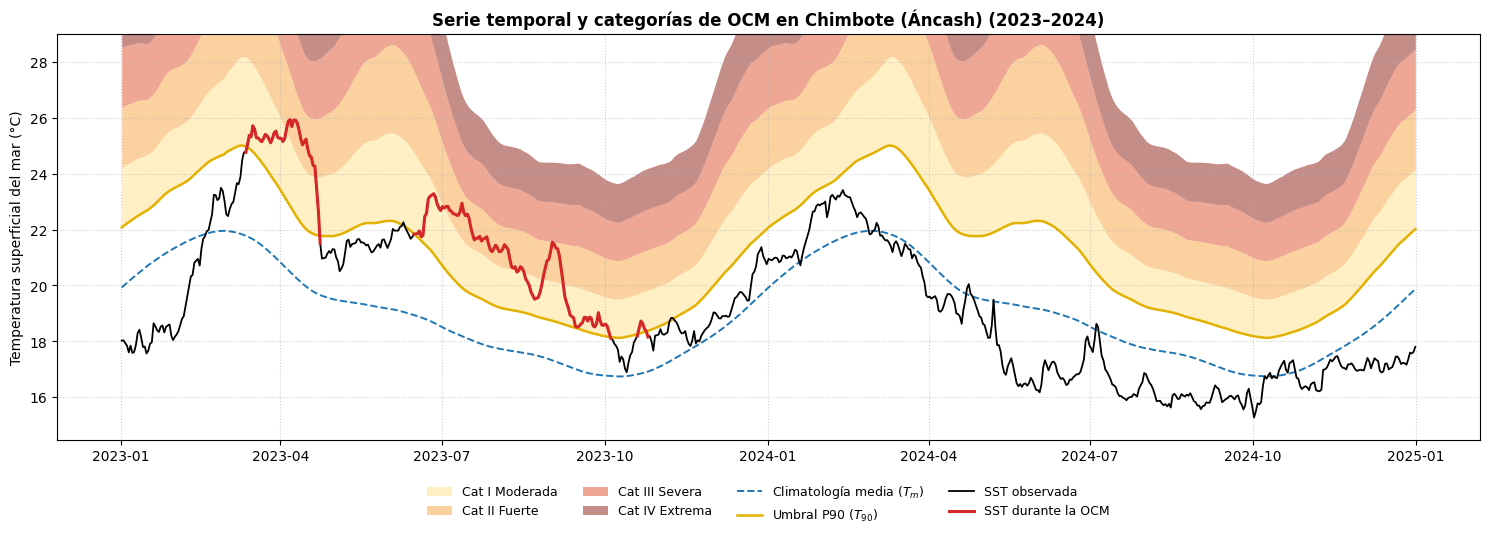

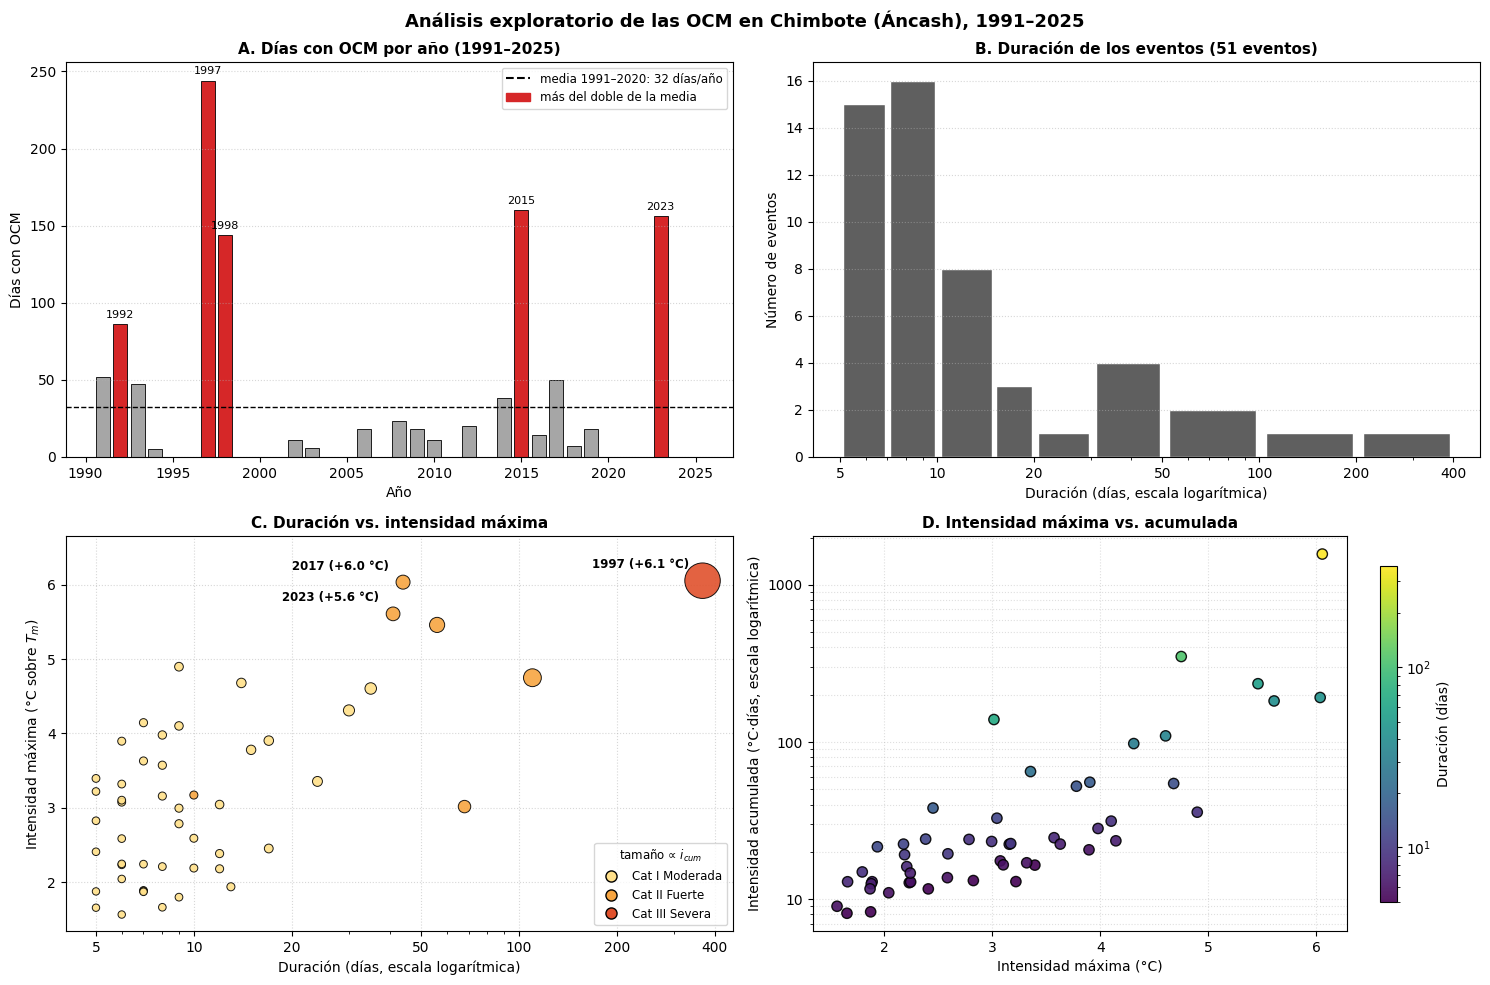

TABLA 1: CARACTERIZACIÓN DE EVENTOS POR CATEGORÍA EN CHIMBOTE (ÁNCASH)


,Categoría,N° Eventos,Duración Media (días),Duración Máx (días),Intensidad Máx Media (°C),Dosis Acum Media (°C·días)
0,Cat I (Moderada),44,9.8,35,2.90,26.0
1,Cat II (Fuerte),6,54.8,110,4.67,186.9
2,Cat III (Severa),1,367.0,367,6.05,1570.6



TABLA 2: TOP 10 EVENTOS HISTÓRICOS MÁS EXTREMOS EN CHIMBOTE (ÁNCASH) (1991–2025)


,Inicio,Término,Duración (días),Intensidad Máx (°C),Dosis Acum (°C·días),Categoría,Fenómeno Asociado
0,1997-05-08,1998-05-09,367,6.05,1570.6,Cat III (Severa),Super El Niño 1997–1998
1,2017-02-15,2017-03-30,44,6.03,192.0,Cat II (Fuerte),El Niño Costero 2017
2,2023-03-13,2023-04-22,41,5.61,182.5,Cat II (Fuerte),El Niño 2023–2024
3,1992-03-22,1992-05-16,56,5.46,235.0,Cat II (Fuerte),El Niño 1991–1992
4,2016-02-23,2016-03-02,9,4.90,35.8,Cat I (Moderada),El Niño 2015–2016
5,2023-06-16,2023-10-03,110,4.75,349.9,Cat II (Fuerte),El Niño 2023–2024
6,2012-06-06,2012-06-19,14,4.68,54.5,Cat I (Moderada),Sin asociación ENOS asignada
7,2015-06-05,2015-07-09,35,4.60,109.5,Cat I (Moderada),El Niño 2015–2016
8,2014-05-07,2014-06-05,30,4.31,97.8,Cat I (Moderada),Sin asociación ENOS asignada
9,2015-04-30,2015-05-06,7,4.14,23.5,Cat I (Moderada),El Niño 2015–2016


In [6]:
# 1. Serie temporal 2023-2024 con las bandas de categoría (Hobday et al., 2018)
# detect() devuelve la SST, T_m y T_90 ya alineados con cada fecha
punto = mask.dataset.isel(lat=ilat, lon=ilon).sel(time=slice("2023-01-01", "2024-12-31"))
t_zoom, sst_zoom, mask_zoom = punto["time"], punto["temperature"], punto["event_membership"]
clim_zoom, umbral_zoom = punto["reference"], punto["threshold"]
dT_zoom = umbral_zoom - clim_zoom

fig, ax = plt.subplots(figsize=(15, 5.5))
for k in range(4):
    ax.fill_between(t_zoom, umbral_zoom + k * dT_zoom, umbral_zoom + (k + 1) * dT_zoom, color=C_CAT[k],
                    alpha=0.5, lw=0, label=f"Cat {NOMBRES_CAT[k]}")
ax.plot(t_zoom, clim_zoom, color=C_CLIM, ls="--", lw=1.4, label="Climatología media ($T_m$)")
ax.plot(t_zoom, umbral_zoom, color=C_UMBRAL, lw=1.8, label="Umbral P90 ($T_{90}$)")
trazar_sst(ax, t_zoom, sst_zoom, mask_zoom)
# Eje y ajustado a los datos: se ven las bandas que la SST llega a alcanzar
ax.set_ylim(float(sst_zoom.min()) - 0.8, max(float(sst_zoom.max()), float((umbral_zoom + dT_zoom).max())) + 0.8)
ax.set_title(f"Serie temporal y categorías de OCM en {nombre_pto_sel} (2023–2024)", fontsize=12, fontweight="bold")
ax.set_ylabel("Temperatura superficial del mar (°C)")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4, frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

# 2. Panel exploratorio (4 gráficos)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import ScalarFormatter

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
cat_evento = df_eventos["category_max"].astype(int)

# A: Días con OCM por año, frente a la media 1991-2020
dias_anuales = mask.dataset["event_membership"].isel(lat=ilat, lon=ilon).groupby("time.year").sum().to_series()
media_ref = dias_anuales.loc[1991:2020].mean()
altos = dias_anuales > 2 * media_ref
ax = axes[0, 0]
ax.bar(dias_anuales.index, dias_anuales, color=np.where(altos, C_OCM, "#a6a6a6"), edgecolor="black", lw=0.6, width=0.8)
ax.axhline(media_ref, color="black", ls="--", lw=1)
for anio in dias_anuales[altos].index:
    ax.text(anio, dias_anuales[anio] + 4, str(anio), ha="center", fontsize=8)
ax.legend(handles=[Line2D([], [], color="black", ls="--", label=f"media 1991–2020: {media_ref:.0f} días/año"),
                   Patch(color=C_OCM, label="más del doble de la media")], loc="upper right", fontsize=8.5)
ax.set_title("A. Días con OCM por año (1991–2025)", fontsize=11, fontweight="bold")
ax.set_xlabel("Año")
ax.set_ylabel("Días con OCM")
ax.grid(True, axis="y", linestyle=":", alpha=0.5)

# B: Duración de los eventos (eje x logarítmico: muchos eventos cortos y pocos muy largos)
ax = axes[0, 1]
ax.hist(df_eventos["duration_days"], bins=[5, 7, 10, 15, 20, 30, 50, 100, 200, 400], color="#5f5f5f",
        edgecolor="white", rwidth=0.9)
ax.set_xscale("log")
ax.set_xticks([5, 10, 20, 50, 100, 200, 400])
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.set_title(f"B. Duración de los eventos ({len(df_eventos)} eventos)", fontsize=11, fontweight="bold")
ax.set_xlabel("Duración (días, escala logarítmica)")
ax.set_ylabel("Número de eventos")
ax.grid(True, axis="y", linestyle=":", alpha=0.5)

# C: Duración vs. intensidad máxima; color = categoría (colores del esquema), tamaño = intensidad acumulada
ax = axes[1, 0]
ax.scatter(df_eventos["duration_days"], df_eventos["intensity_max"], s=df_eventos["intensity_cumulative"] * 0.4 + 25,
           c=[C_CAT[k - 1] for k in cat_evento], edgecolor="black", linewidth=0.7, alpha=0.9, zorder=3)
for _, fila in df_eventos.nlargest(3, "intensity_max").iterrows():
    ax.annotate(f"{fila['start'].year} (+{fila['intensity_max']:.1f} °C)", (fila["duration_days"], fila["intensity_max"]),
                textcoords="offset points", xytext=(-10, 9), ha="right", fontsize=8.5, fontweight="bold")
ax.set_xscale("log")
ax.set_xticks([5, 10, 20, 50, 100, 200, 400])
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.set_ylim(top=df_eventos["intensity_max"].max() + 0.6)
ax.legend(handles=[Line2D([], [], marker="o", ls="", markersize=8, markerfacecolor=C_CAT[k - 1], markeredgecolor="black",
                          label=f"Cat {NOMBRES_CAT[k - 1]}") for k in sorted(cat_evento.unique())],
          loc="lower right", fontsize=8.5, title="tamaño ∝ $i_{cum}$", title_fontsize=8.5)
ax.set_title("C. Duración vs. intensidad máxima", fontsize=11, fontweight="bold")
ax.set_xlabel("Duración (días, escala logarítmica)")
ax.set_ylabel("Intensidad máxima (°C sobre $T_m$)")
ax.grid(True, linestyle=":", alpha=0.5)

# D: Intensidad máxima vs. acumulada (eje y logarítmico: la acumulada abarca tres órdenes de magnitud)
ax = axes[1, 1]
sc = ax.scatter(df_eventos["intensity_max"], df_eventos["intensity_cumulative"], c=df_eventos["duration_days"],
                cmap="viridis", norm=matplotlib.colors.LogNorm(), edgecolor="black", s=55, alpha=0.9, zorder=3)
cbar = plt.colorbar(sc, ax=ax, shrink=0.85)
cbar.set_label("Duración (días)")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(ScalarFormatter())
ax.set_title("D. Intensidad máxima vs. acumulada", fontsize=11, fontweight="bold")
ax.set_xlabel("Intensidad máxima (°C)")
ax.set_ylabel("Intensidad acumulada (°C·días, escala logarítmica)")
ax.grid(True, which="both", linestyle=":", alpha=0.4)

plt.suptitle(f"Análisis exploratorio de las OCM en {nombre_pto_sel}, 1991–2025", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# 3. Tabla 1: Estadísticas Descriptivas por Categoría (Hobday et al., 2018)
nombres_cat = {1: "Cat I (Moderada)", 2: "Cat II (Fuerte)", 3: "Cat III (Severa)", 4: "Cat IV (Extrema)"}
tabla_cat = df_eventos.groupby("category_max").agg(
    n_eventos=("event_id", "count"),
    duracion_media=("duration_days", "mean"),
    duracion_max=("duration_days", "max"),
    intensidad_max_prom=("intensity_max", "mean"),
    intensidad_acum_prom=("intensity_cumulative", "mean")
).reset_index()

tabla_cat["Categoría"] = tabla_cat["category_max"].map(nombres_cat)
tabla_cat_display = tabla_cat[["Categoría", "n_eventos", "duracion_media", "duracion_max", "intensidad_max_prom", "intensidad_acum_prom"]].copy()
tabla_cat_display.columns = ["Categoría", "N° Eventos", "Duración Media (días)", "Duración Máx (días)", "Intensidad Máx Media (°C)", "Dosis Acum Media (°C·días)"]
tabla_cat_display["Duración Media (días)"] = tabla_cat_display["Duración Media (días)"].round(1)
tabla_cat_display["Intensidad Máx Media (°C)"] = tabla_cat_display["Intensidad Máx Media (°C)"].round(2)
tabla_cat_display["Dosis Acum Media (°C·días)"] = tabla_cat_display["Dosis Acum Media (°C·días)"].round(1)

print("=" * 75)
print(f"TABLA 1: CARACTERIZACIÓN DE EVENTOS POR CATEGORÍA EN {nombre_pto_sel.upper()}")
print("=" * 75)
try:
    display(tabla_cat_display)
except NameError:
    print(tabla_cat_display.to_string(index=False))

# 4. Tabla 2: Top 10 Eventos Históricos Más Extremos en Chimbote
top_10 = df_eventos.sort_values(by="intensity_max", ascending=False).head(10).copy()

def asociar_fenomeno(row):
    yr = row["start"].year
    if yr in [1991, 1992]:
        return "El Niño 1991–1992"
    elif yr in [1997, 1998]:
        return "Super El Niño 1997–1998"
    elif yr in [2015, 2016]:
        return "El Niño 2015–2016"
    elif yr == 2017:
        return "El Niño Costero 2017"
    elif yr in [2023, 2024]:
        return "El Niño 2023–2024"
    else:
        return "Sin asociación ENOS asignada"

top_10["Fenómeno Asociado"] = top_10.apply(asociar_fenomeno, axis=1)
top_10["Categoría"] = top_10["category_max"].map(nombres_cat)

top_10_display = top_10[["start", "end", "duration_days", "intensity_max", "intensity_cumulative", "Categoría", "Fenómeno Asociado"]].copy()
top_10_display["start"] = top_10_display["start"].dt.strftime("%Y-%m-%d")
top_10_display["end"] = top_10_display["end"].dt.strftime("%Y-%m-%d")
top_10_display.columns = ["Inicio", "Término", "Duración (días)", "Intensidad Máx (°C)", "Dosis Acum (°C·días)", "Categoría", "Fenómeno Asociado"]
top_10_display["Intensidad Máx (°C)"] = top_10_display["Intensidad Máx (°C)"].round(2)
top_10_display["Dosis Acum (°C·días)"] = top_10_display["Dosis Acum (°C·días)"].round(1)

print()
print("=" * 75)
print(f"TABLA 2: TOP 10 EVENTOS HISTÓRICOS MÁS EXTREMOS EN {nombre_pto_sel.upper()} (1991–2025)")
print("=" * 75)
try:
    display(top_10_display.reset_index(drop=True))
except NameError:
    print(top_10_display.reset_index(drop=True).to_string(index=False))

## 5. Análisis Espacial y Temporal de las OCM en la Costa Peruana

### 5.1 Comparación Latitudinal: Zonas Norte, Centro y Sur de Perú

**¿Cuáles son las 3 localizaciones representativas de la costa peruana?**

Para evaluar cómo se propagan las anomalías térmicas a lo largo del gradiente latitudinal de la Corriente de Humboldt, seleccionamos tres puertos representativos:

1. **Zona Norte: Paita (Piura: 5.08°S, 81.11°W)**
   - Zona de transición entre aguas tropicales ecuatoriales y la Corriente de Humboldt. Es el punto de mayor impacto directo de las ondas Kelvin costeras y el foco térmico de los eventos de **El Niño Costero**.
2. **Zona Centro: Chimbote (Áncash: 9.07°S, 78.59°W)**
   - Corazón del sistema de afloramiento costero peruano y centro neurálgico de la pesquería pelágica (anchoveta).
3. **Zona Sur: Ilo (Moquegua: 17.64°S, 71.34°W)**
   - Extremo sur del litoral, con un afloramiento intenso y persistente y menor influencia directa de las ondas Kelvin ecuatoriales.

En cada caso usamos el **píxel oceánico más cercano** al puerto (sección 3.2). Visualizamos las 3 localizaciones antes de comparar su respuesta térmica frente a **El Niño Costero 2017** y **El Niño 2023–2024**.

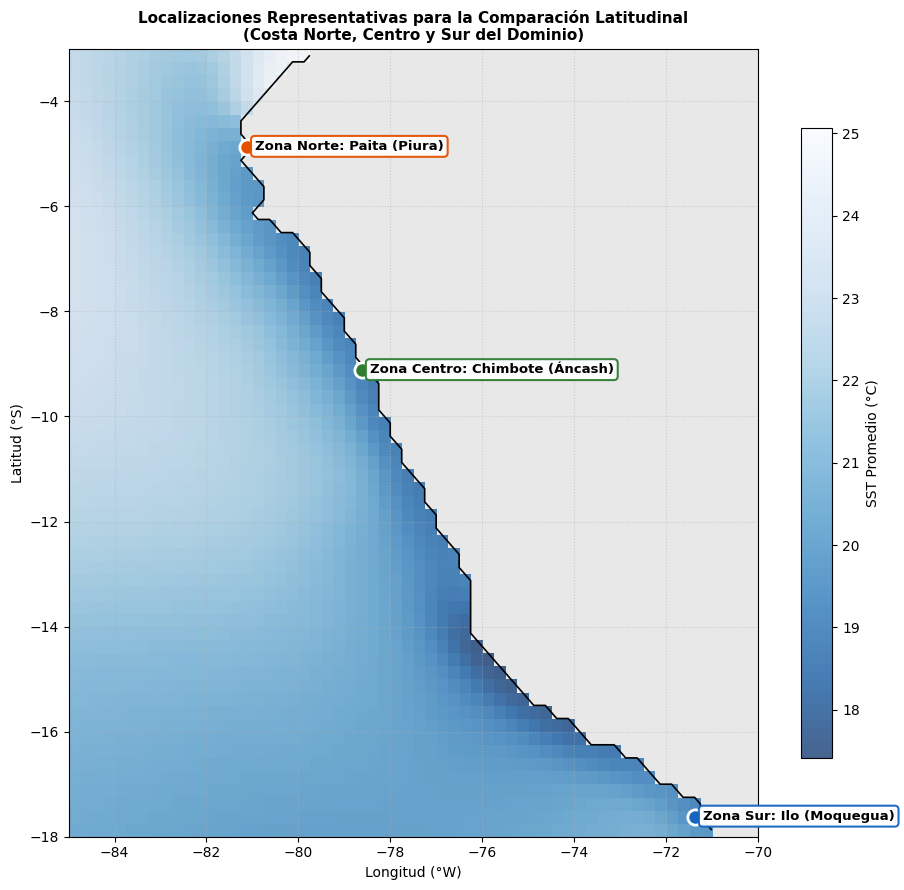

In [7]:
# Mapa de las 3 Localizaciones Representativas de la Costa Peruana
puertos_comparacion = {
    "Zona Norte: Paita (Piura)": puertos_peru["Paita"],
    "Zona Centro: Chimbote (Áncash)": puertos_peru["Chimbote"],
    "Zona Sur: Ilo (Moquegua)": puertos_peru["Ilo"],
}

colores_loc = {
    "Zona Norte: Paita (Piura)": "#e65100",    # Naranja cálido
    "Zona Centro: Chimbote (Áncash)": "#2e7d32", # Verde bosque
    "Zona Sur: Ilo (Moquegua)": "#1565c0"       # Azul cobalto
}

fig, ax = plt.subplots(figsize=(9.5, 9))
ax.set_facecolor("#e8e8e8")
ax.set_aspect("equal")

# Temperatura promedio de fondo
im = sst_mean_map.plot.imshow(ax=ax, cmap="Blues_r", alpha=0.75, cbar_kwargs={'label': 'SST Promedio (°C)', 'shrink': 0.8})
ax.contour(ds["lon"], ds["lat"], ds["domain_mask"], levels=[0.5], colors="black", linewidths=1.2)

# Marcar las 3 localizaciones representativas con badges destacados
for nombre, (p_lat, p_lon) in puertos_comparacion.items():
    p_lat, p_lon = pixel_oceanico(p_lat, p_lon)[2:4]
    col = colores_loc[nombre]
    ax.plot(p_lon, p_lat, marker="o", color=col, markeredgecolor="white", markeredgewidth=2, markersize=11, zorder=6)
    ax.text(p_lon + 0.18, p_lat - 0.05, nombre, color="black", fontsize=9.5, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=col, linewidth=1.5, alpha=0.95), zorder=7)

ax.set_title("Localizaciones Representativas para la Comparación Latitudinal\n(Costa Norte, Centro y Sur del Dominio)", fontsize=11, fontweight="bold")
ax.set_xlabel("Longitud (°W)")
ax.set_ylabel("Latitud (°S)")
ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

# Función para comparar las 3 localizaciones en un periodo
def comparar_puertos_en_evento(puertos_dict, fecha_ini, fecha_fin, titulo_evento):
    fig, axes = plt.subplots(len(puertos_dict), 1, figsize=(15, 3.8 * len(puertos_dict)), sharex=True)

    for ax, (nombre, (p_lat, p_lon)) in zip(axes, puertos_dict.items()):
        col = colores_loc[nombre]
        p_lat, p_lon = pixel_oceanico(p_lat, p_lon)[2:4]   # centro del píxel oceánico más cercano
        punto = mask.dataset.sel(lat=p_lat, lon=p_lon, method="nearest").sel(time=slice(fecha_ini, fecha_fin))
        sst_p, en_ocm = punto["temperature"], punto["event_membership"].values

        ax.plot(sst_p.time, punto["reference"], color=C_CLIM, linestyle="--", linewidth=1.1, label="Climatología Media ($T_m$)")
        ax.plot(sst_p.time, punto["threshold"], color=C_UMBRAL, linestyle="-.", linewidth=1.3, label="Umbral P90 ($T_{90}$)")
        trazar_sst(ax, sst_p.time, sst_p, en_ocm)

        ax.set_title(f"{nombre} (Lat: {float(sst_p.lat):.2f}°, Lon: {float(sst_p.lon):.2f}°) | Total días de OCM: {int(en_ocm.sum())}",
                     fontsize=11, fontweight="bold", color=col)
        ax.set_ylabel("SST (°C)")
        ax.grid(True, linestyle=":", alpha=0.5)
    fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.965), ncol=4,
               frameon=False, fontsize=10)
    axes[-1].set_xlabel("Fecha")
    plt.suptitle(titulo_evento, fontsize=13, fontweight="bold", y=0.995)
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

### 5.2 Contraste: El Niño Costero 2017 vs. El Niño 2023–2024

Comparamos la firma térmica y el alcance latitudinal de ambos fenómenos.

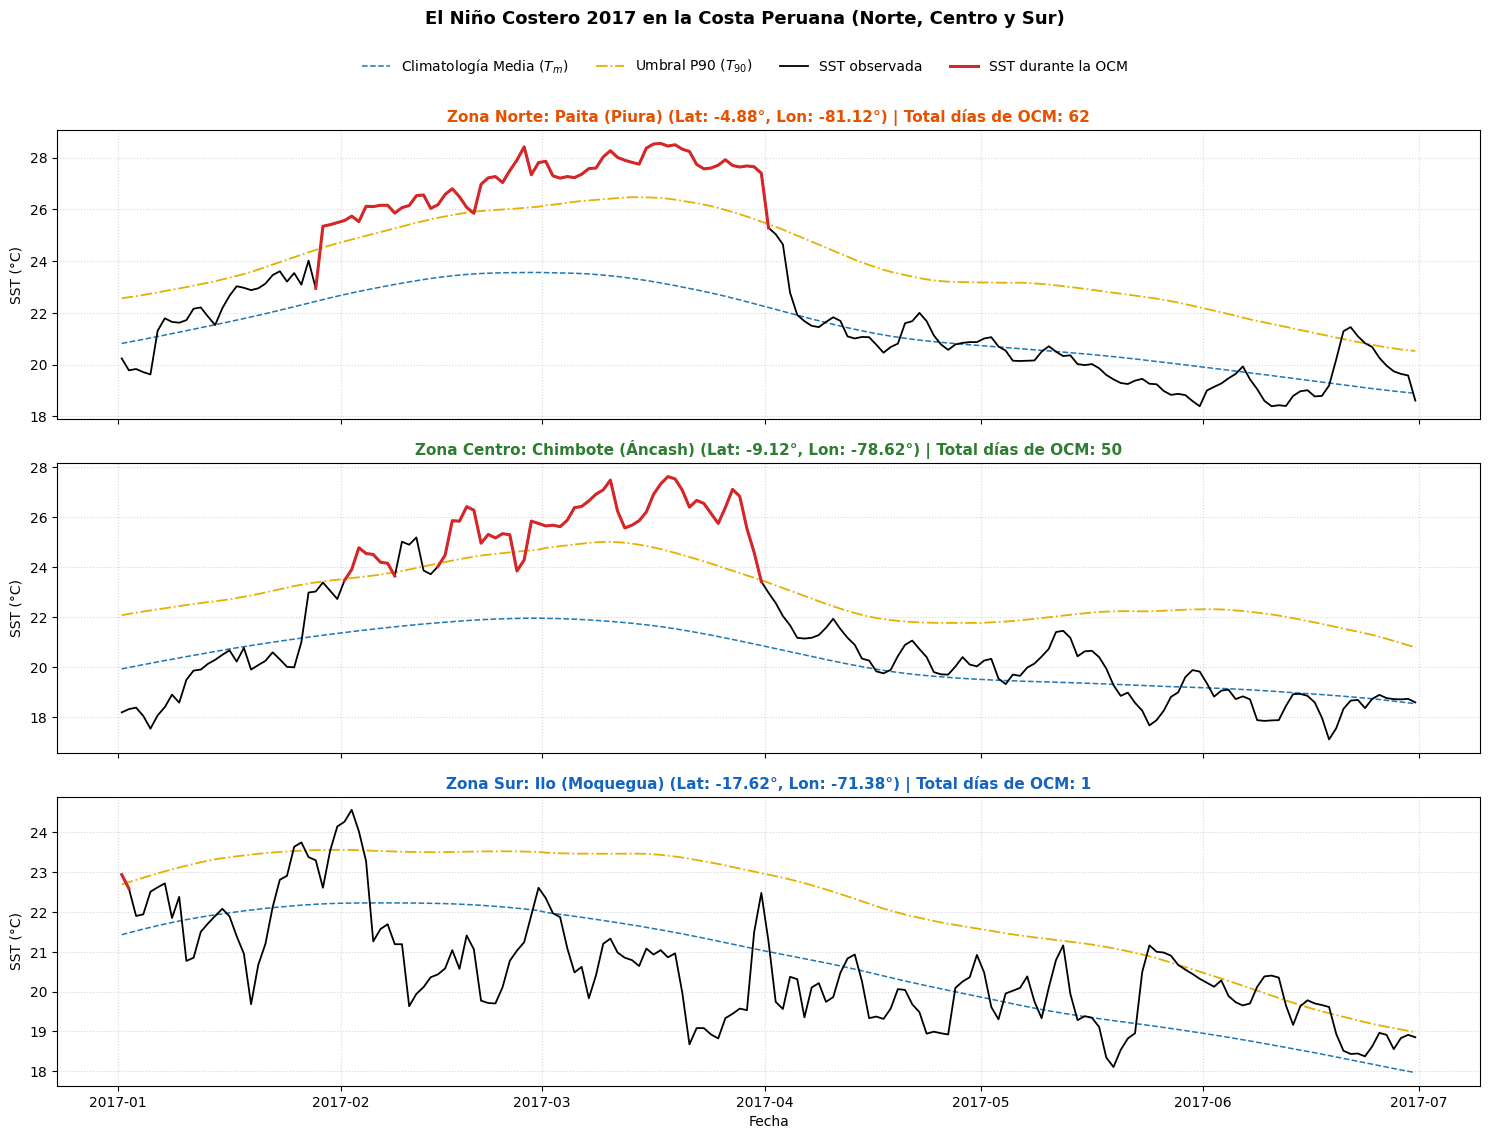

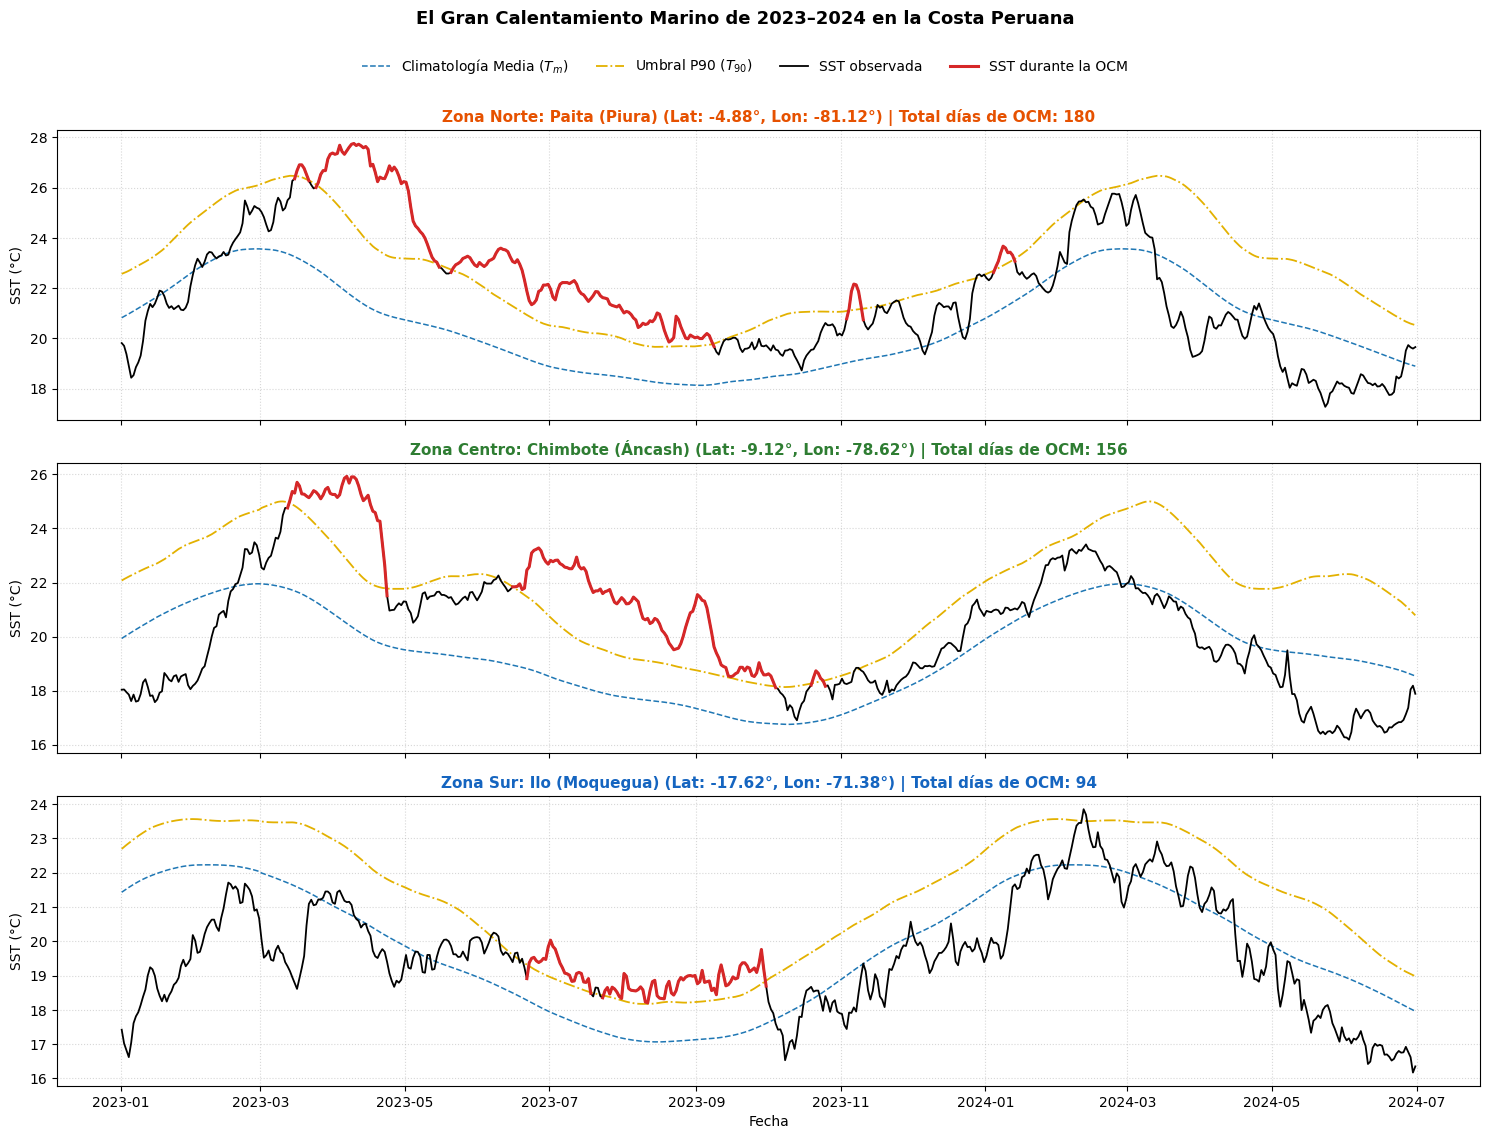

In [8]:
# 1. El Niño Costero 2017 (foco térmico en el norte)
comparar_puertos_en_evento(puertos_comparacion, "2017-01-01", "2017-06-30",
                           "El Niño Costero 2017 en la Costa Peruana (Norte, Centro y Sur)")

# 2. El Niño 2023–2024 (impacto a lo largo de todo el litoral)
comparar_puertos_en_evento(puertos_comparacion, "2023-01-01", "2024-06-30",
                           "El Gran Calentamiento Marino de 2023–2024 en la Costa Peruana")

### 5.3 Patrones espaciales de las OCM

**Series regionales en la franja costera**

Para las series por región promediamos solo la **franja costera**: celdas oceánicas a no más de 4 píxeles (≈1°, ≈110 km) de tierra. Promediar todo el ancho del dominio (hasta 85°W) mezclaría la señal costera con océano abierto. Mostramos la **anomalía mensual** respecto de 1991–2020: sin el ciclo estacional, los eventos cálidos se ven mucho mejor que en la SST diaria.

**¿Cómo se tratan adecuadamente los mapas en oceanografía y ciencias del clima?**

1. **Aspect Ratio Cartográfico Riguroso (`ax.set_aspect('equal')`):** En mallas regulares de latitud/longitud, Matplotlib deforma los píxeles si ajusta la figura a la ventana. Fijar un aspecto 1:1 asegura que cada grado espacial sea geográficamente coherente y los píxeles no se estiren artificialmente.
2. **Máscara Continental y Fondo Neutro:** El continente debe tener un tono neutro distintivo (gris `#e8e8e8`) para que no se confunda con los valores mínimos o nulos de la paleta oceánica.
3. **Contorno Nítido de Línea de Costa:** El trazo negro continuo del litoral ayuda a contextualizar la distancia costera de las masas de agua anómala.
4. **Contexto Geográfico con Puertos:** Localizar los puertos de referencia (**Paita, Chicama, Salaverry, Chimbote, Callao, Pisco, San Juan de Marcona, Ilo**) permite relacionar la señal física con la geografía pesquera real.
5. **Selección de Paleta Cromática para Días Activos:**
   - Para **Días con OCM Activa**, evitamos `YlOrRd` (cuyo inicio amarillo pálido se funde con el fondo y tiene poco contraste) y empleamos **`turbo`**: una paleta continua de amplio rango dinámico que distingue claramente desde 0 hasta >500 días.
   - Para la **Intensidad máxima** (°C), empleamos **`plasma`**: una escala perceptualmente uniforme que va desde tonos oscuros hasta amarillo incandescente.
   - Para la **Categoría máxima** usamos los cuatro colores de los esquemas (I a IV) y blanco para las celdas sin OCM.
   - Para la **Intensidad acumulada** (°C·días), empleamos **`magma`**: resume en un número la intensidad y la duración de todas las OCM del periodo.

La categoría de cada día es $\lfloor (T - T_m)/\Delta T \rfloor$ (de I a IV, 2.3); el mapa muestra la mayor categoría alcanzada en cada celda.

Celdas en la franja costera: 272


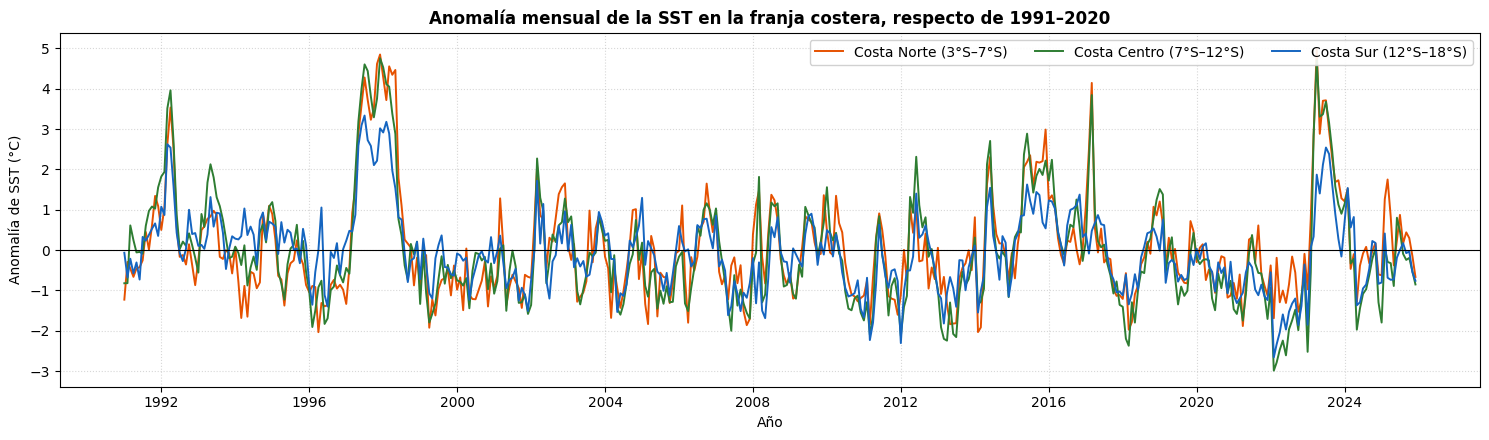

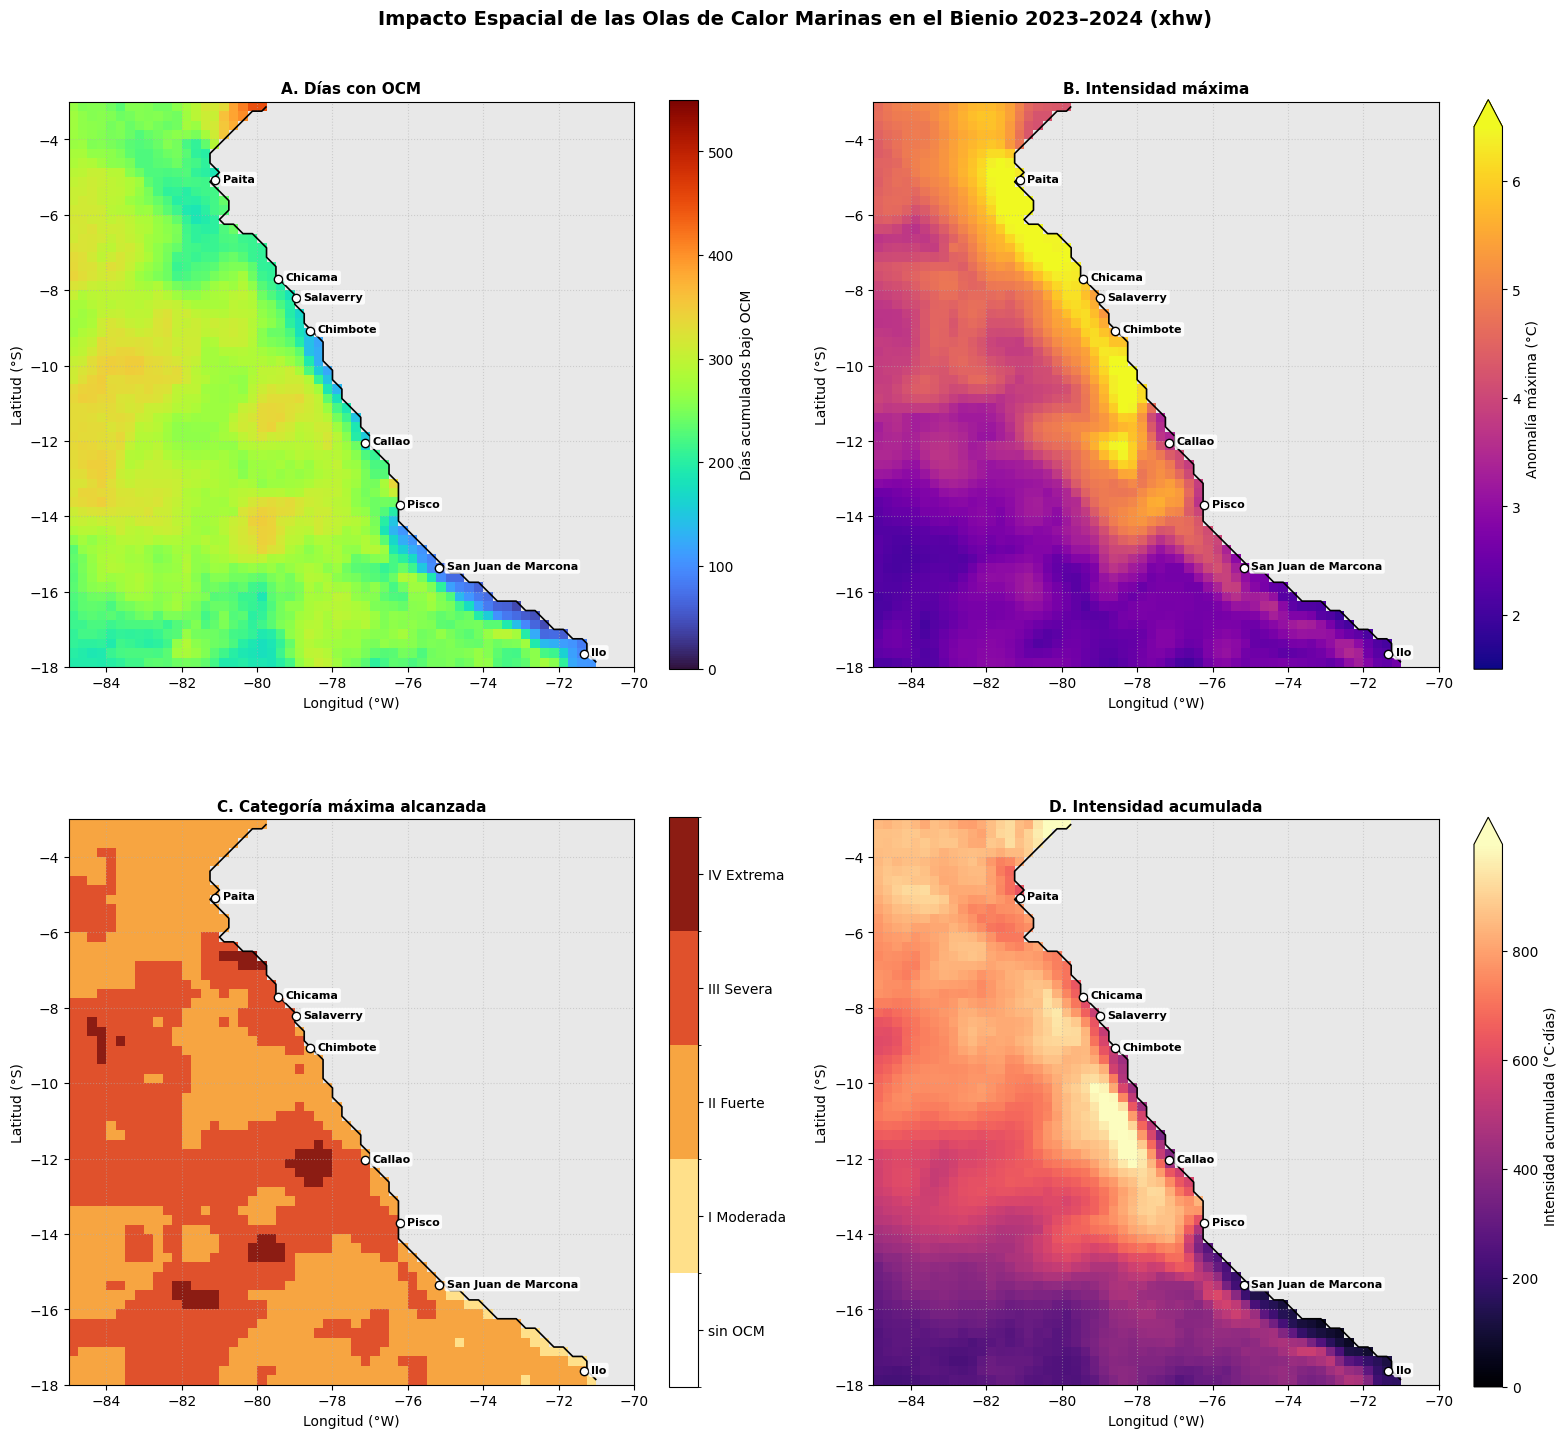

Celdas oceánicas por categoría máxima 2023–2024: sin OCM: 0, I: 17, II: 890, III: 847, IV: 51


In [9]:
# 1. Series de tiempo promedio por regiones latitudinales en la franja costera (≤ 4 píxeles de tierra)
from scipy.ndimage import binary_dilation
tierra = ~ds["domain_mask"].values
franja = xr.DataArray(binary_dilation(tierra, iterations=4) & ~tierra,
                      dims=("lat", "lon"), coords={"lat": ds.lat, "lon": ds.lon})
sst_costa = ds["sst"].where(franja)
sst_norte = sst_costa.sel(lat=slice(-7.0, -3.0)).mean(dim=("lat", "lon"))
sst_centro = sst_costa.sel(lat=slice(-12.0, -7.0)).mean(dim=("lat", "lon"))
sst_sur = sst_costa.sel(lat=slice(-18.0, -12.0)).mean(dim=("lat", "lon"))
print(f"Celdas en la franja costera: {int(franja.sum())}")

fig, ax = plt.subplots(figsize=(15, 4.5))
regiones = {"Costa Norte (3°S–7°S)": (sst_norte, "#e65100"), "Costa Centro (7°S–12°S)": (sst_centro, "#2e7d32"),
            "Costa Sur (12°S–18°S)": (sst_sur, "#1565c0")}
for nombre, (serie, color) in regiones.items():
    mensual = serie.resample(time="MS").mean()
    clim_mensual = mensual.sel(time=slice("1991", "2020")).groupby("time.month").mean()
    anomalia_mensual = mensual.groupby("time.month") - clim_mensual
    ax.plot(anomalia_mensual.time, anomalia_mensual, color=color, lw=1.4, label=nombre)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Anomalía mensual de la SST en la franja costera, respecto de 1991–2020", fontsize=12, fontweight="bold")
ax.set_xlabel("Año")
ax.set_ylabel("Anomalía de SST (°C)")
ax.legend(loc="upper right", ncol=3, frameon=True, framealpha=0.9)
ax.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

# 2. Métricas por celda del bienio 2023-2024 (a partir de la salida de detect)
periodo = mask.dataset.sel(time=slice("2023-01-01", "2024-12-31"))
en_ocm = periodo["event_membership"]
oceano = ds["domain_mask"]
anomalia = periodo["temperature"] - periodo["reference"]
delta_t = periodo["threshold"] - periodo["reference"]

dias_mhw_23_24 = en_ocm.sum("time").where(oceano)                        # tierra -> NaN (gris)
intensidad_max_23_24 = anomalia.where(en_ocm).max("time")
icum_23_24 = anomalia.where(en_ocm).sum("time").where(oceano)
categoria_dia = np.floor(anomalia / delta_t).clip(1, 4)                    # I..IV (Hobday et al., 2018)
categoria_max_23_24 = categoria_dia.where(en_ocm).max("time").fillna(0).where(oceano)   # 0 = sin OCM


def decorar_mapa(ax, tam_marcador=6):
    """Fondo gris (tierra), aspecto 1:1, línea de costa y puertos."""
    ax.set_facecolor("#e8e8e8")
    ax.set_aspect("equal")
    ax.contour(ds["lon"], ds["lat"], ds["domain_mask"], levels=[0.5], colors="black", linewidths=1.2)
    for nombre, (p_lat, p_lon) in puertos_peru.items():
        ax.plot(p_lon, p_lat, marker="o", color="white", markeredgecolor="black", markersize=tam_marcador, zorder=6)
        ax.text(p_lon + 0.2, p_lat - 0.05, nombre, color="black", fontsize=8, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.85, edgecolor="none"), zorder=7)
    ax.set_xlabel("Longitud (°W)", fontsize=10)   # xarray reemplaza las etiquetas al graficar
    ax.set_ylabel("Latitud (°S)", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.5)


# 3. Mapas 2x2: días, intensidad máxima, categoría máxima e intensidad acumulada
fig, axes = plt.subplots(2, 2, figsize=(16, 15))
dias_mhw_23_24.plot(ax=axes[0, 0], cmap="turbo", vmin=0, vmax=550,
                    cbar_kwargs={"label": "Días acumulados bajo OCM", "shrink": 0.8})
axes[0, 0].set_title("A. Días con OCM", fontsize=11, fontweight="bold")

intensidad_max_23_24.plot(ax=axes[0, 1], cmap="plasma", vmin=1.5, vmax=6.5,
                          cbar_kwargs={"label": "Anomalía máxima (°C)", "shrink": 0.8})
axes[0, 1].set_title("B. Intensidad máxima", fontsize=11, fontweight="bold")

cmap_cat = ListedColormap(["white"] + C_CAT)
im = categoria_max_23_24.plot(ax=axes[1, 0], cmap=cmap_cat, norm=BoundaryNorm(np.arange(-0.5, 5), cmap_cat.N),
                              add_colorbar=False)
cbar = fig.colorbar(im, ax=axes[1, 0], shrink=0.8, ticks=range(5))
cbar.ax.set_yticklabels(["sin OCM", "I Moderada", "II Fuerte", "III Severa", "IV Extrema"])
axes[1, 0].set_title("C. Categoría máxima alcanzada", fontsize=11, fontweight="bold")

icum_23_24.plot(ax=axes[1, 1], cmap="magma", vmin=0, vmax=float(icum_23_24.quantile(0.99)),
                cbar_kwargs={"label": "Intensidad acumulada (°C·días)", "shrink": 0.8})
axes[1, 1].set_title("D. Intensidad acumulada", fontsize=11, fontweight="bold")

for ax in axes.flat:
    decorar_mapa(ax)
plt.suptitle("Impacto Espacial de las Olas de Calor Marinas en el Bienio 2023–2024 (xhw)", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

cats = categoria_max_23_24.values[oceano.values]
print("Celdas oceánicas por categoría máxima 2023–2024: " +
      ", ".join(f"{n}: {int((cats == k).sum())}" for k, n in enumerate(["sin OCM", "I", "II", "III", "IV"])))

## 6. Comparación con la librería de Eric Oliver (`marineHeatWaves`)

La implementación de referencia canónica en la literatura es el paquete `marineHeatWaves` desarrollado por **Eric C. J. Oliver** (Hobday et al., 2016).

Comparamos ambas librerías a la luz de los **cuatro contratos científicos** de especificación:

| Contrato | Eric Oliver (`marineHeatWaves`) | Implementación `xhw` | Equivalencia / Diferencias |
| :--- | :--- | :--- | :--- |
| **`SourceRef`** | No desacoplado; asume series temporales 1D en memoria. | Objeto explícito de procedencia (`dataset_id`, `version`, `accessed`). | `xhw` asegura reproducibilidad FAIR de datos de entrada. |
| **`GridSpec`** | Estrictamente 1D puntual (requiere bucles manuales para mallas 2D). | Mallas N-dimensionales nativas (`structured`, `unstructured`, `point`, `volume`). | `xhw` procesa dominios completos con vectorización y Dask. |
| **`DefinitionSpec`** | Parámetros sueltos (`pctile=90`, `minDuration=5`, `joinAcrossGaps=True`). | Contrato declarativo inmutable (`DefinitionSpec`). | Mismos eventos en el píxel de Chimbote. Climatología y umbral difieren < 0.002 °C solo en ~35 días alrededor del 1-ene: para fines de diciembre, la ventana de ±5 días de Oliver toma días de enero de 2021 (fuera del periodo de referencia) si la serie continúa; `xhw` usa una ventana estricta dentro de 1991–2020 (decisión ADR-031 de `xhw`). Si a Oliver se le da la serie solo hasta 2020, la diferencia baja a ~1e-7 °C. En todo el dominio 1991–2025 eso cambia ≈0.001 % de los días-celda, siempre en diciembre–enero. |
| **`BaselineSpec`** | Climatología fija (30 años), interpola 29-feb, suavizado circular de 31d. | Soporta líneas base fijas (`fixed_climatology`) y dinámicas con validación. | `xhw` implementa la misma interpolación y suavizado circular. |

**Cómo medimos el tiempo.** Para que la comparación sea justa, ambas librerías hacen las mismas tareas sobre **todas las celdas oceánicas** del dominio: climatología, umbral P90 y detección de eventos. El tiempo de `xhw` es el del pipeline completo de la sección 4.1 (`fit_baseline` + `detect` + `build_catalog`); el de Oliver es el del bucle celda por celda de la celda siguiente. Los datos ya están en memoria en ambos casos.

> ⏱️ El bucle de Oliver sobre todo el dominio tarda varios minutos (≈0.1 s por celda).

marineHeatWaves (Oliver): 51 eventos detectados en 0.110 s
xhw:                      51 eventos detectados
Discrepancia en conteo:   0 eventos (Coincidencia exacta: True)
Máx |Δ climatología| = 1.59e-03 °C
Máx |Δ umbral P90|   = 6.78e-04 °C


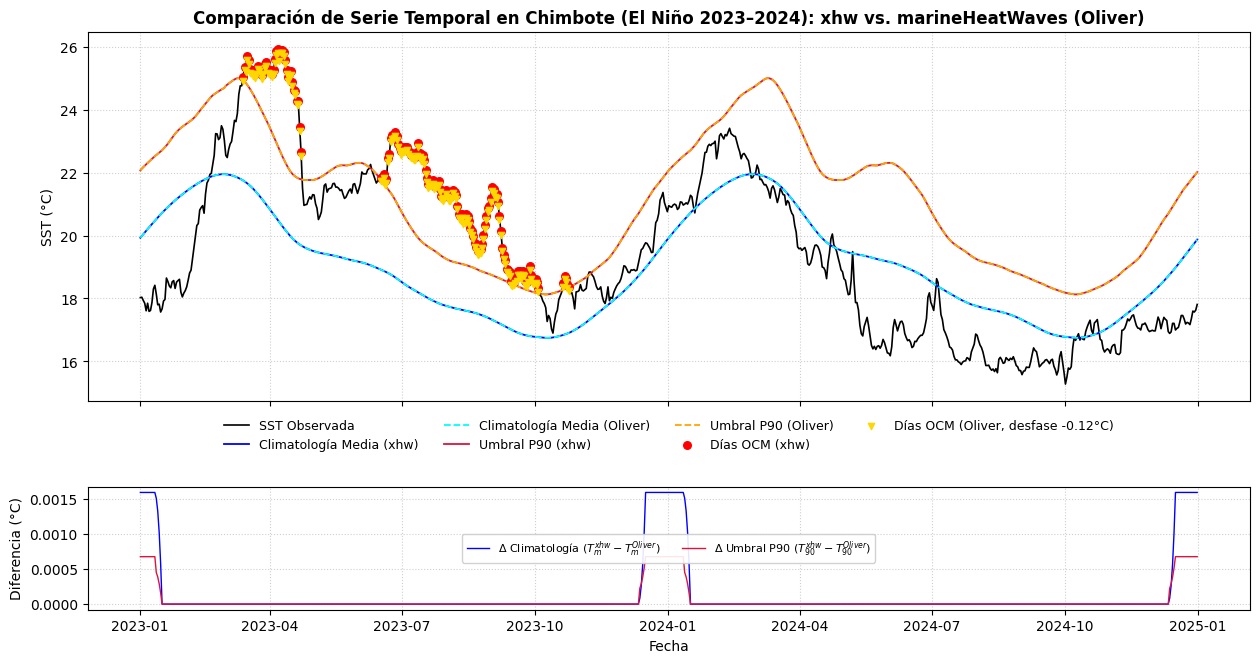

In [10]:
# 1. Serie temporal completa en Chimbote (mismo píxel oceánico que en la sección 4)
sst_pt = ds.sst.isel(lat=ilat, lon=ilon)
t_dates = sst_pt.time.values
t_ordinal = np.array([pd.Timestamp(dt).to_pydatetime().toordinal() for dt in t_dates])
temp_vals = sst_pt.values

# 2. Ejecutar detección con marineHeatWaves de Eric Oliver
t0_oliver = time.time()
mhws_oliver, clim_oliver = mhw_oliver.detect(
    t_ordinal, temp_vals,
    climatologyPeriod=[1991, 2020],
    pctile=90,
    windowHalfWidth=5,
    smoothPercentileWidth=31,
    minDuration=5,
    maxGap=2
)
tiempo_oliver_pt = time.time() - t0_oliver

print(f"marineHeatWaves (Oliver): {mhws_oliver['n_events']} eventos detectados en {tiempo_oliver_pt:.3f} s")
print(f"xhw:                      {len(df_eventos)} eventos detectados")
print(f"Discrepancia en conteo:   {abs(len(df_eventos) - mhws_oliver['n_events'])} eventos (Coincidencia exacta: {len(df_eventos) == mhws_oliver['n_events']})")

# Diferencias numéricas en todo el periodo (climatología y umbral día a día)
punto_xhw = mask.dataset.isel(lat=ilat, lon=ilon)
clim_xhw_full = punto_xhw["reference"].values
thr_xhw_full = punto_xhw["threshold"].values
print(f"Máx |Δ climatología| = {np.nanmax(np.abs(clim_xhw_full - clim_oliver['seas'])):.2e} °C")
print(f"Máx |Δ umbral P90|   = {np.nanmax(np.abs(thr_xhw_full - clim_oliver['thresh'])):.2e} °C")

# 3. Preparar series para la comparación temporal (2023–2024)
t_dates_pd = pd.to_datetime(t_dates)
idx_23_24 = np.where((t_dates_pd >= "2023-01-01") & (t_dates_pd <= "2024-12-31 23:59:59"))[0]
sst_23_24_ts = sst_pt.sel(time=slice("2023-01-01", "2024-12-31"))
clim_xhw = clim_xhw_full[idx_23_24]
umbral_xhw = thr_xhw_full[idx_23_24]
mask_xhw = punto_xhw["event_membership"].values[idx_23_24]

clim_oliver_ts = clim_oliver["seas"][idx_23_24]
umbral_oliver_ts = clim_oliver["thresh"][idx_23_24]
ev_mem_oliver = np.zeros_like(temp_vals, dtype=bool)
for ev in range(mhws_oliver["n_events"]):
    ev_mem_oliver[mhws_oliver["index_start"][ev]:mhws_oliver["index_end"][ev]+1] = True
mask_oliver = ev_mem_oliver[idx_23_24]

# 4. Gráfica Comparativa de Serie Temporal con Análisis de Residuos
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 7.5), sharex=True, gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.35})

# Panel 1: Series temporales
ax1.plot(sst_23_24_ts.time, sst_23_24_ts.values, color="black", linewidth=1.2, label="SST Observada")
ax1.plot(sst_23_24_ts.time, clim_xhw, color="blue", linestyle="-", linewidth=1.3, label="Climatología Media (xhw)")
ax1.plot(sst_23_24_ts.time, clim_oliver_ts, color="cyan", linestyle="--", linewidth=1.3, label="Climatología Media (Oliver)")
ax1.plot(sst_23_24_ts.time, umbral_xhw, color="crimson", linestyle="-", linewidth=1.3, label="Umbral P90 (xhw)")
ax1.plot(sst_23_24_ts.time, umbral_oliver_ts, color="orange", linestyle="--", linewidth=1.3, label="Umbral P90 (Oliver)")

ax1.scatter(sst_23_24_ts.time.values[mask_xhw], sst_23_24_ts.values[mask_xhw], color="red", s=30, zorder=5, label="Días OCM (xhw)")
ax1.scatter(sst_23_24_ts.time.values[mask_oliver], sst_23_24_ts.values[mask_oliver] - 0.12, color="gold", marker="v", s=20, zorder=6, label="Días OCM (Oliver, desfase -0.12°C)")
ax1.set_title("Comparación de Serie Temporal en Chimbote (El Niño 2023–2024): xhw vs. marineHeatWaves (Oliver)", fontsize=12, fontweight="bold")
ax1.set_ylabel("SST (°C)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=4, frameon=False, fontsize=9)

# Panel 2: Diferencia Residual
diff_clim = clim_xhw - clim_oliver_ts
diff_thresh = umbral_xhw - umbral_oliver_ts
ax2.plot(sst_23_24_ts.time, diff_clim, color="blue", linewidth=1.0, label="Δ Climatología ($T_{m}^{xhw} - T_{m}^{Oliver}$)")
ax2.plot(sst_23_24_ts.time, diff_thresh, color="crimson", linewidth=1.0, label="Δ Umbral P90 ($T_{90}^{xhw} - T_{90}^{Oliver}$)")
ax2.set_ylabel("Diferencia (°C)")
ax2.set_xlabel("Fecha")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="center", ncol=2, framealpha=0.9, fontsize=8)

plt.show()

### 6.1 ¿Detectan los mismos eventos?

Emparejamos los eventos de ambas librerías en Chimbote por sus fechas de inicio y fin, y comparamos sus métricas.

In [11]:
# Eventos de Oliver en una tabla con los mismos nombres que el catálogo de xhw
fechas_pt = pd.to_datetime(t_dates).normalize()
categorias_oliver = {"Moderate": 1, "Strong": 2, "Severe": 3, "Extreme": 4}
ev_oliver = pd.DataFrame({
    "start": fechas_pt[mhws_oliver["index_start"]],
    "end": fechas_pt[mhws_oliver["index_end"]],
    "duration_days": mhws_oliver["duration"],
    "intensity_max": mhws_oliver["intensity_max"],
    "intensity_cumulative": mhws_oliver["intensity_cumulative"],
    "category_max": [categorias_oliver[c] for c in mhws_oliver["category"]],
})
ev_xhw = df_eventos.assign(start=df_eventos["start"].dt.normalize(), end=df_eventos["end"].dt.normalize())
cols = ["start", "end", "duration_days", "intensity_max", "intensity_cumulative", "category_max"]
pares = ev_xhw[cols].merge(ev_oliver, on=["start", "end"], how="outer", suffixes=("_xhw", "_oliver"), indicator=True)
comunes = pares[pares["_merge"] == "both"]

resumen = pd.DataFrame([
    ("Eventos detectados", len(ev_xhw), len(ev_oliver)),
    ("Días bajo OCM (1991–2025)", int(ev_xhw["duration_days"].sum()), int(ev_oliver["duration_days"].sum())),
    ("Eventos con las mismas fechas de inicio y fin", len(comunes), len(comunes)),
    ("Eventos que solo detecta una librería", int((pares["_merge"] == "left_only").sum()), int((pares["_merge"] == "right_only").sum())),
    ("Eventos comunes con la misma categoría máxima",
     int((comunes["category_max_xhw"] == comunes["category_max_oliver"]).sum()), "–"),
    ("Máx |Δ intensidad máxima| en eventos comunes (°C)",
     f"{(comunes['intensity_max_xhw'] - comunes['intensity_max_oliver']).abs().max():.1e}", "–"),
    ("Máx |Δ intensidad acumulada| en eventos comunes (°C·días)",
     f"{(comunes['intensity_cumulative_xhw'] - comunes['intensity_cumulative_oliver']).abs().max():.1e}", "–"),
], columns=["Indicador", "xhw", "Oliver"])

try:
    display(resumen.set_index("Indicador"))
except NameError:
    print(resumen.to_string(index=False))

distintos = pares[pares["_merge"] != "both"]
if len(distintos):
    print("Eventos sin pareja:")
    print(distintos[["start", "end", "_merge"]].to_string(index=False))

,xhw,Oliver
Indicador,,
Eventos detectados,51,51
Días bajo OCM (1991–2025),1128,1128
Eventos con las mismas fechas de inicio y fin,51,51
Eventos que solo detecta una librería,0,0
Eventos comunes con la misma categoría máxima,51,–
Máx |Δ intensidad máxima| en eventos comunes (°C),1.6e-03,–
Máx |Δ intensidad acumulada| en eventos comunes (°C·días),4.9e-02,–


**Resultado en Chimbote.** Las dos librerías detectan los **mismos 51 eventos**, con las mismas fechas de inicio y fin, la misma categoría máxima y los mismos 1128 días bajo OCM. Las métricas difieren en milésimas: hasta 0,0016 °C en la intensidad máxima y 0,05 °C·días en la acumulada.

Esas milésimas vienen de la climatología, que difiere hasta 0,0016 °C y solo alrededor del 1 de enero. Para los últimos días de diciembre, la ventana de ±5 días de Oliver toma días de enero de 2021, que ya están fuera del periodo de referencia; `xhw` se limita estrictamente a 1991–2020. Una diferencia tan pequeña solo cambia la detección si la SST queda justo en el umbral, y en Chimbote eso no ocurre.

### 6.2 Todo el dominio: tiempo de cómputo y diferencias espaciales

Repetimos la detección de Oliver celda por celda en las 1805 celdas oceánicas y la comparamos con los mapas de `xhw` de la sección 5.3. Los mapas de la derecha muestran la **diferencia Oliver − xhw**: blanco significa que ambas librerías dan exactamente lo mismo.

Calculando detección espacial con marineHeatWaves celda por celda en celdas oceánicas...


Oliver 2D completado en 191.4 s
xhw (pipeline completo, sección 4.1) en 16.03 s  ->  aceleración ≈ 12x sobre 1805 celdas oceánicas (mismas tareas: climatología, umbral y detección)
Celdas con distinto número de días OCM (2023-2024): 15 de 1805
Máx |Δ días OCM|: 6  |  Máx |Δ intensidad máxima|: 5.73e-07 °C


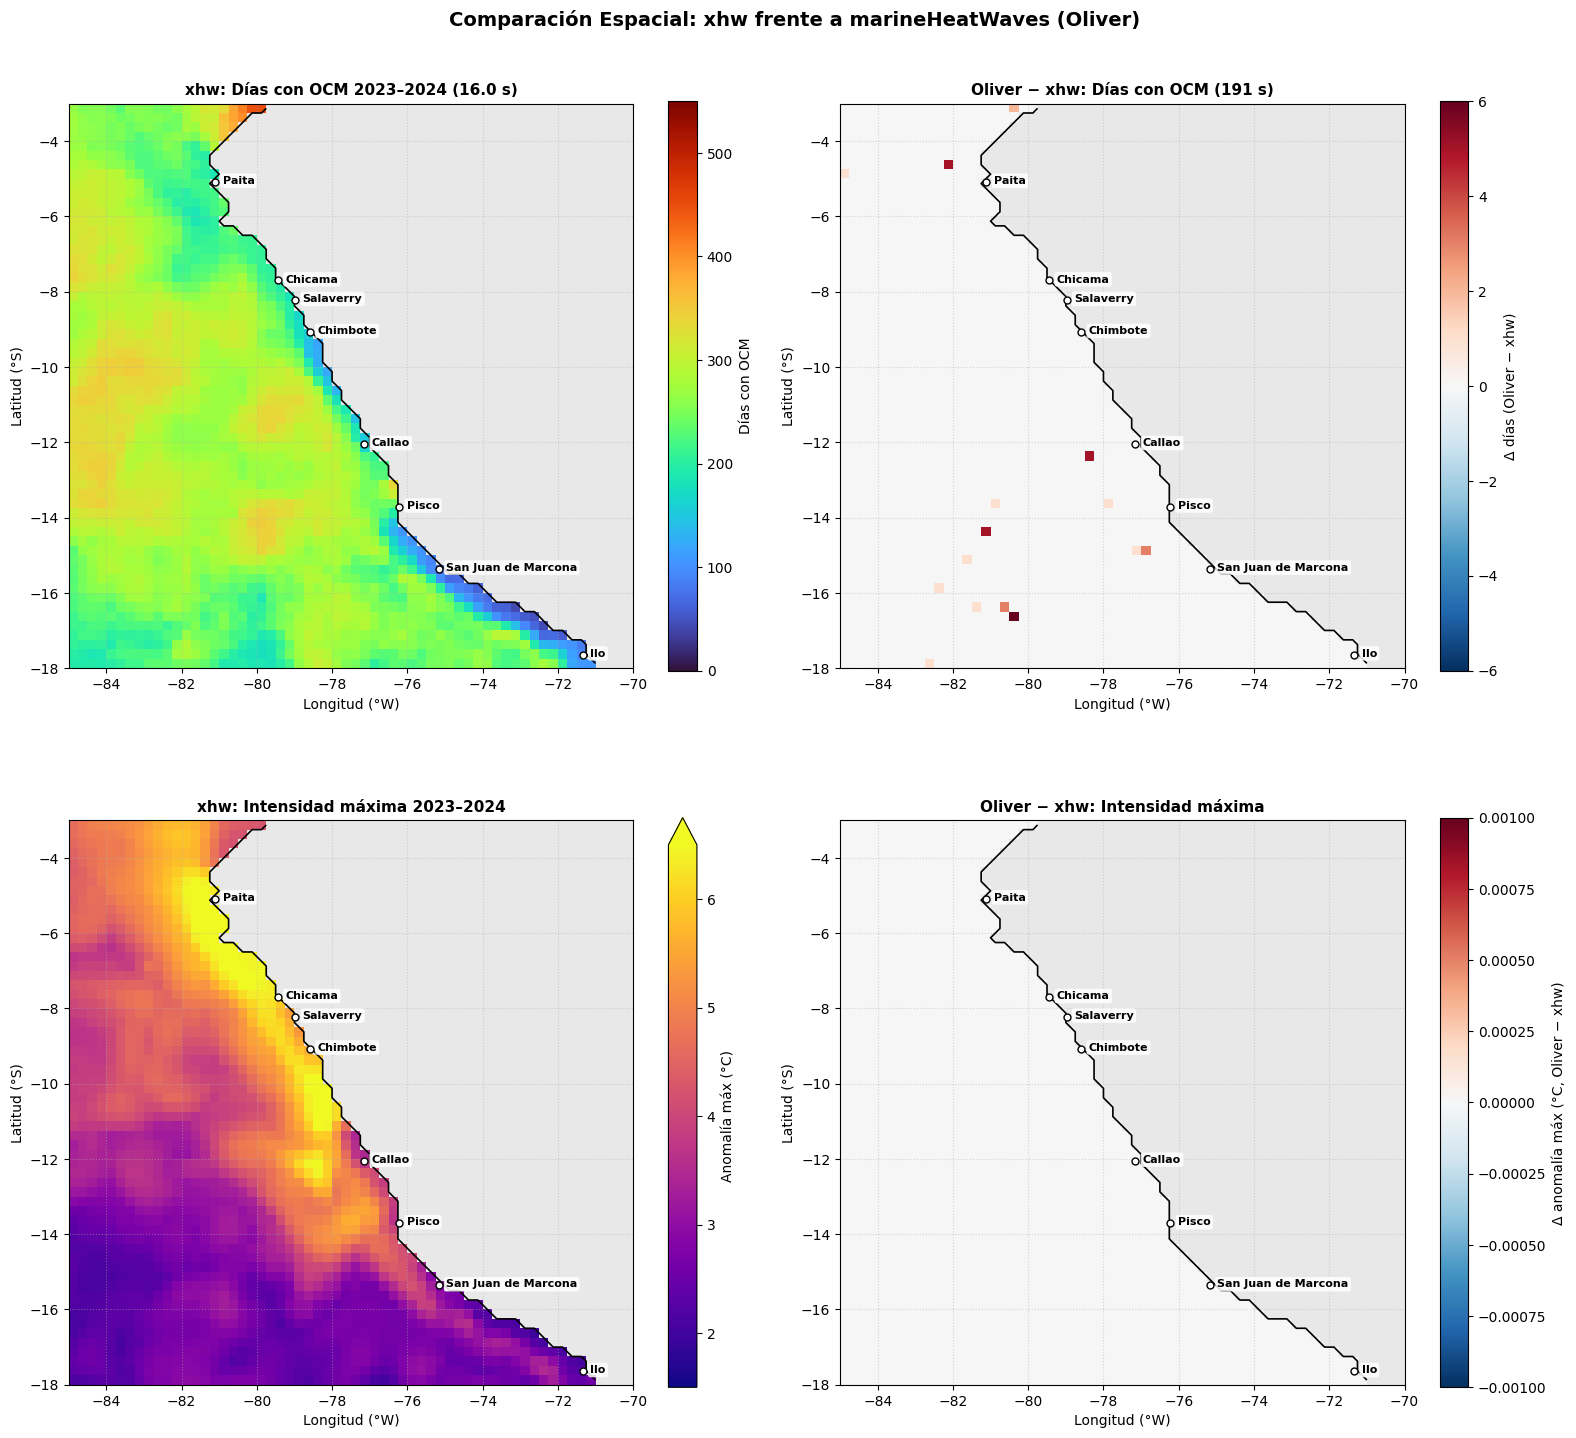

In [ ]:
print("Calculando detección espacial con marineHeatWaves celda por celda en celdas oceánicas...")
t0_oliver_2d = time.time()
nlats, nlons = ds.sizes["lat"], ds.sizes["lon"]
oliver_days = np.full((nlats, nlons), np.nan)
oliver_imax = np.full((nlats, nlons), np.nan)

sst_np = ds.sst.values            # arreglo en memoria (time, lat, lon)
oceano_np = ds.domain_mask.values

# Detección celda por celda con Oliver (únicamente celdas oceánicas)
for i in range(nlats):
    for j in range(nlons):
        if not oceano_np[i, j]:
            continue
        sst_ij = sst_np[:, i, j]
        res_ij, clim_ij = mhw_oliver.detect(
            t_ordinal, sst_ij,
            climatologyPeriod=[1991, 2020],
            pctile=90,
            windowHalfWidth=5,
            smoothPercentileWidth=31,
            minDuration=5,
            maxGap=2
        )
        ev_mem = np.zeros_like(sst_ij, dtype=bool)
        for ev in range(res_ij["n_events"]):
            ev_mem[res_ij["index_start"][ev]:res_ij["index_end"][ev]+1] = True
        ev_23_24 = ev_mem[idx_23_24]
        oliver_days[i, j] = np.sum(ev_23_24)
        anom = (sst_ij[idx_23_24] - clim_ij["seas"][idx_23_24])[ev_23_24]
        if len(anom) > 0:
            oliver_imax[i, j] = np.max(anom)

tiempo_oliver_2d = time.time() - t0_oliver_2d
n_celdas = int(oceano_np.sum())
print(f"Oliver 2D completado en {tiempo_oliver_2d:.1f} s")
print(f"xhw (pipeline completo, sección 4.1) en {tiempo_xhw_total:.2f} s  ->  aceleración ≈ {tiempo_oliver_2d / tiempo_xhw_total:.0f}x "
      f"sobre {n_celdas} celdas oceánicas (mismas tareas: climatología, umbral y detección)")

# Diferencias Oliver - xhw (mapas de xhw de la sección 5.3)
dif_dias = np.where(oceano_np, oliver_days - dias_mhw_23_24.values, np.nan)
dif_imax = oliver_imax - intensidad_max_23_24.values
print(f"Celdas con distinto número de días OCM (2023-2024): {int((np.abs(dif_dias) > 0).sum())} de {n_celdas}")
print(f"Máx |Δ días OCM|: {np.nanmax(np.abs(dif_dias)):.0f}  |  Máx |Δ intensidad máxima|: {np.nanmax(np.abs(dif_imax)):.2e} °C")

extent = [float(ds.lon.min()) - 0.125, float(ds.lon.max()) + 0.125, float(ds.lat.min()) - 0.125, float(ds.lat.max()) + 0.125]
lim_dias = max(1, np.nanmax(np.abs(dif_dias)))
lim_imax = max(1e-3, np.nanmax(np.abs(dif_imax)))

fig, axes = plt.subplots(2, 2, figsize=(16, 15))
dias_mhw_23_24.plot(ax=axes[0, 0], cmap="turbo", vmin=0, vmax=550, cbar_kwargs={"label": "Días con OCM", "shrink": 0.8})
axes[0, 0].set_title(f"xhw: Días con OCM 2023–2024 ({tiempo_xhw_total:.1f} s)", fontsize=11, fontweight="bold")
im = axes[0, 1].imshow(dif_dias, origin="lower", extent=extent, cmap="RdBu_r", vmin=-lim_dias, vmax=lim_dias)
fig.colorbar(im, ax=axes[0, 1], label="Δ días (Oliver − xhw)", shrink=0.8)
axes[0, 1].set_title(f"Oliver − xhw: Días con OCM ({tiempo_oliver_2d:.0f} s)", fontsize=11, fontweight="bold")

intensidad_max_23_24.plot(ax=axes[1, 0], cmap="plasma", vmin=1.5, vmax=6.5, cbar_kwargs={"label": "Anomalía máx (°C)", "shrink": 0.8})
axes[1, 0].set_title("xhw: Intensidad máxima 2023–2024", fontsize=11, fontweight="bold")
im = axes[1, 1].imshow(dif_imax, origin="lower", extent=extent, cmap="RdBu_r", vmin=-lim_imax, vmax=lim_imax)
fig.colorbar(im, ax=axes[1, 1], label="Δ anomalía máx (°C, Oliver − xhw)", shrink=0.8)
axes[1, 1].set_title("Oliver − xhw: Intensidad máxima", fontsize=11, fontweight="bold")

for ax in axes.flat:
    decorar_mapa(ax, tam_marcador=5)
plt.suptitle("Comparación Espacial: xhw frente a marineHeatWaves (Oliver)", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

**Resultado en todo el dominio.** `xhw` resuelve las 1805 celdas en **16 s** y Oliver tarda **191 s**: unas 12 veces más rápido en esta ejecución (la razón varía con la carga del equipo).

Los resultados coinciden en 1790 de las 1805 celdas. En las otras 15, Oliver cuenta entre 1 y 6 días más de OCM en 2023–2024: 37 días-celda en total, 36 en diciembre o enero y 1 en febrero. Es la misma diferencia de climatología de 6.1: allí la SST quedó justo entre los dos umbrales, y un día más sobre el umbral basta para alargar un evento o para que una racha llegue a los 5 días. La intensidad máxima coincide en todo el dominio (diferencia ≤ 6·10⁻⁷ °C).

## 7. Resumen y perspectivas

### Conclusiones del taller
1. **Rigor metodológico.** La definición de Hobday et al. (2016, 2018) separa las anomalías breves de los eventos persistentes y gradúa su severidad con categorías e intensidad acumulada, de forma comparable entre lugares y estudios.
2. **El Niño domina las OCM de la costa peruana.** Los años con más días de OCM son años de El Niño. En promedio sobre el dominio, una celda pasó 244 días bajo OCM en 2023, 233 en 1997, 154 en 1998 y 108 en 2015. En Chimbote, el evento de 1997–1998 duró 367 días y fue el único de categoría III. La intensidad acumulada separa los grandes eventos (1571 °C·días) de los moderados (26 °C·días en promedio en la categoría I).
3. **2017 y 2023–2024 fueron fenómenos distintos.** El Niño Costero 2017 se concentró en el norte: entre enero y junio de 2017, Paita sumó 62 días de OCM, Chimbote 50 e Ilo apenas 1. El calentamiento de 2023–2024 alcanzó todo el litoral (180, 156 y 94 días entre enero de 2023 y junio de 2024) y casi todo el dominio: el 96 % de las celdas oceánicas pasó al menos 180 días bajo OCM, y la mayoría llegó a la categoría II (890 celdas) o III (847).
4. **Costa y mar abierto.** En 2023–2024 la franja costera (≈ 110 km) acumuló menos días de OCM que el mar abierto (mediana de 214 frente a 279 días), pero las mayores intensidades, máxima y acumulada, se dieron cerca de la costa, entre Chicama y Pisco. El afloramiento costero acorta los eventos, pero no impide que sean intensos.
5. **Más días de OCM en los últimos años, pero no en toda la costa.** Respecto de 1991–2020, el promedio del dominio pasa de 31 a 58 días de OCM por año en 2021–2025, impulsado por 2023. En la costa el cambio no es uniforme: Paita pasa de 31 a 43 días por año, Chimbote se mantiene (32 → 31) e Ilo baja (30 → 19). La perspectiva final discute cómo separar los eventos de la tendencia de fondo.
6. **Eficiencia y escalabilidad.** La implementación de Oliver recorre el dominio celda por celda; `xhw` resuelve el dominio completo (climatología, umbral y detección de 1805 celdas) en segundos: 16 s frente a 191 s en esta ejecución, y entre 12 y 23 veces más rápido según la carga del equipo. Al operar sobre mallas completas, `xhw` escala a dominios globales y a proyecciones climáticas.
7. **Equivalencia numérica.** Ambas librerías detectan los mismos eventos en Chimbote y coinciden en 1790 de 1805 celdas en 2023–2024. Las diferencias, de pocos días y siempre en diciembre–febrero, vienen de que Oliver deja que la ventana de ±5 días de fin de año tome días de enero de 2021, fuera del periodo de referencia, mientras que `xhw` se limita a 1991–2020.

### Perspectiva: líneas base que siguen el calentamiento

Todo el taller usa una **línea base fija** (1991–2020), como Hobday et al. (2016) y el paquete de Oliver. Esa elección responde a la pregunta *¿cuán cálido está el mar respecto del clima de 1991–2020?* En un océano que se calienta, los últimos años quedan cada vez más por encima de esa climatología y las OCM se vuelven más largas y frecuentes, hasta parecer casi permanentes. Si la pregunta es otra, *¿cuán extremo es este evento respecto del clima actual?*, la línea base tiene que moverse con el calentamiento.

Bonino et al. (2023) lo resuelven con una descomposición **STL**: temperatura = tendencia + estacionalidad + residuo, y el umbral es tendencia + estacionalidad + percentil 90 del residuo. `xhw` ofrece esa línea base (`method="stl"`) y otras dinámicas (`detrended`, `shifting`, …), que el paquete de Oliver no tiene. La definición de OCM no cambia, solo la línea base:

```python
from dataclasses import replace
baseline_stl = replace(baseline, method="stl", params=(("engine", "vectorized"),))
```

![Línea base fija frente a línea base STL](assets/esquema_linea_base_stl.png)

En la serie sintética de la figura, con 0,3 °C de calentamiento por década, ambas líneas base dan unos 27 días de OCM por año en 1991–2020. En 2021–2025 la línea base fija da 125 días por año y la STL, 51. Las ventanas por defecto de `xhw` no son las del artículo de Bonino et al., así que la figura ilustra la idea, no reproduce su método.